# Front-of-package nutrition labels RCT benchmark

In [4]:
import gc, json, sys, traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from cycler import cycler
from IPython.display import display
from tqdm.auto import tqdm

CODE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kev").is_dir())
for p in (CODE_DIR, CODE_DIR / "kev"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from models.kev_pointer import KevPointerModel

LANCET_PALETTE = ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"]
plt.rcParams["axes.prop_cycle"] = cycler(color=LANCET_PALETTE)

DATA_PATH = (
    Path("ParentFile_wide.csv")
    if Path("ParentFile_wide.csv").exists()
    else CODE_DIR / "data/nutrition/Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases/ParentFile_wide.csv"
)
raw_df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(raw_df):,} respondents x {raw_df.shape[1]} columns from {DATA_PATH.name}")
raw_df[["participantid", "foplcond", "age", "gender", "educ", "income", "idbev", "rhelp", "rsupport"]].head()

Loaded 5,636 respondents x 87 columns from ParentFile_wide.csv


,participantid,foplcond,age,gender,educ,income,idbev,rhelp,rsupport
0,000EDE20B49148C6B225823CC6D64AF7,Positive,49,1.0,3.0,6.0,3.0,5.0,4.0
1,0019A30A1F2C41C685A9CE494181EED2,Positive+NutritionInfo,33,1.0,5.0,7.0,1.0,4.0,4.0
2,001A93FD6D314F7BBD9CD777D31B462E,Positive+HighIn,20,3.0,3.0,3.0,1.0,4.0,5.0
3,001DDAF9DA1F46618158D81D24E81EEB,HighIn,48,1.0,2.0,1.0,1.0,5.0,4.0
4,002D321B2814496DA6BDA3438A04F646,Spectrum,52,2.0,5.0,6.0,1.0,1.0,5.0


## 1. Codebook mappings, label stimuli, and respondent personas

In [5]:
AGE_BINS = [17, 29, 49, 64, 120]
AGE_LABELS = ["18-29", "30-49", "50-64", "65+"]

PERSONA_NAMES = {
    "c_alphan": "Country",
    "SEX": "Sex",
    "AGE": "Age",
    "EDULEVEL": "Education",
    "US_INC": "Income",
    "RACE": "Race",
    "HISPANIC": "Hispanic or Latino",
    "SNAP": "SNAP / Food Stamps recipient",
    "NFPUSE": "Nutrition Facts label usage",
    "ONLINEAMT": "Share of groceries bought online",
    "HEALTHLIT": "Nutrition literacy score",
}

FOPL_STIMULUS = {
    "Positive": (
        "Blue star badge showing '[* GOOD]' (1 star), '[** BETTER]' (2 stars), or '[*** BEST]' (3 stars) "
        "on qualifying products; no front-of-package label on other products."
    ),
    "NutritionInfo": (
        "White box with magnifying glass icon on all products reading 'Nutrition Info | Per serving | "
        "Saturated Fat: Low (green) / Med (yellow) / High (red) | "
        "Sodium: Low (green) / Med (yellow) / High (red) | "
        "Added Sugars: Low (green) / Med (yellow) / High (red) | FDA.gov'."
    ),
    "HighIn": (
        "White box with magnifying glass icon reading 'High In | [Saturated Fat / Sodium / Added Sugars] | FDA.gov' "
        "when a product is high in those nutrients; no front-of-package label on other products."
    ),
    "Positive+NutritionInfo": (
        "Blue star badge ('[* GOOD]', '[** BETTER]', or '[*** BEST]' when earned) alongside white box on all products "
        "reading 'Nutrition Info | Per serving | Saturated Fat: Low (green) / Med (yellow) / High (red) | "
        "Sodium: Low (green) / Med (yellow) / High (red) | Added Sugars: Low (green) / Med (yellow) / High (red) | FDA.gov'."
    ),
    "Positive+HighIn": (
        "Blue star badge ('[* GOOD]', '[** BETTER]', or '[*** BEST]' when earned) alongside white box "
        "reading 'High In | [Saturated Fat / Sodium / Added Sugars] | FDA.gov' (when high in those nutrients); "
        "no front-of-package label on other products."
    ),
    "Spectrum": (
        "Color-coded 1-to-5 star badge on all products reading '[* POOR]' (1 star, red), '[** FAIR]' (2 stars, orange), "
        "'[*** GOOD]' (3 stars, yellow), '[**** BETTER]' (4 stars, light green), or '[***** BEST]' (5 stars, dark green)."
    ),
}

PRODUCT_BASE_LABELS = {
    "idbev": {
        "Ocean Spray 100% Cranberry juice": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: Low (green) | FDA.gov",
            None,
            "[** FAIR (2 stars, orange)]",
        ),
        "Ocean Spray Cranberry Juice Cocktail": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: High (red) | FDA.gov",
            "High In: Added Sugars | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    "idbread": {
        "Mission Extra Thin Corn Tortillas": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: Low (green) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "Mission Flour Burrito Tortillas": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: High (red), Added Sugars: Low (green) | FDA.gov",
            "High In: Sodium | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    "idcereal": {
        "Post Selects Great Grains Crunchy Pecans": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Med (yellow), Added Sugars: Med (yellow) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "General Mills Chocolate Chex Gluten Free Cereal": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Med (yellow), Added Sugars: High (red) | FDA.gov",
            "High In: Added Sugars | FDA.gov",
            "[** FAIR (2 stars, orange)]",
        ),
    },
    "idsoup": {
        "Campbell's Healthy Request Chunk Sirloin Burger Soup": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: Med (yellow), Added Sugars: Low (green) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "Dinty Moore Beef Stew": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: High (red), Added Sugars: Low (green) | FDA.gov",
            "High In: Sodium | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    "idsnack": {
        "Sun Chips Original multigrain snacks": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Med (yellow), Added Sugars: Low (green) | FDA.gov",
            None,
            "[** FAIR (2 stars, orange)]",
        ),
        "Nutella & Go! Cup": (
            None,
            "Nutrition Info Per serving - Saturated Fat: High (red), Sodium: Med (yellow), Added Sugars: High (red) | FDA.gov",
            "High In: Saturated Fat, Added Sugars | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    "idmeal": {
        "Healthy Choice Cafe Steamers Chicken Marinara": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: Med (yellow), Added Sugars: Low (green) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "Lean Cuisine Turkey with Dressing": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: High (red), Added Sugars: Med (yellow) | FDA.gov",
            "High In: Sodium | FDA.gov",
            "[** FAIR (2 stars, orange)]",
        ),
    },
}


def format_product_label(qid, product_name, arm):
    pos_b, ninfo_b, highin_b, spec_b = PRODUCT_BASE_LABELS[qid][product_name]
    if arm == "Positive":
        badge = pos_b
    elif arm == "NutritionInfo":
        badge = ninfo_b
    elif arm == "HighIn":
        badge = highin_b
    elif arm == "Positive+NutritionInfo":
        badge = f"{pos_b}; {ninfo_b}" if pos_b is not None else ninfo_b
    elif arm == "Positive+HighIn":
        parts = [b for b in (pos_b, highin_b) if b is not None]
        badge = "; ".join(parts) if parts else None
    elif arm == "Spectrum":
        badge = spec_b
    else:
        raise ValueError(f"Unexpected arm {arm!r}")

    if badge is None:
        return "Front-of-package label: None"
    return f"Front-of-package label: {badge}"


def build_product_criteria(qid, option_texts, arm):
    p1, p2, same_opt = option_texts
    return {
        p1: format_product_label(qid, p1, arm),
        p2: format_product_label(qid, p2, arm),
        same_opt: None,
    }


GENDER_MAP = {1.0: "Female", 2.0: "Male", 3.0: "Non-binary", 4.0: "Other"}
LATINO_MAP = {0.0: "No", 1.0: "Yes"}
RACE_MAP = {
    "Amer Ind AK Native": "American Indian or Alaska Native",
    "Asian": "Asian",
    "Black": "Black or African American",
    "Native Hawaiian or Pacific Islander": "Native Hawaiian or Pacific Islander",
    "White": "White",
    "Other or multi-racial": "Other or multi-racial",
}
EDUC_MAP = {
    1.0: "Less than high school",
    2.0: "High school graduate (or GED)",
    3.0: "Some college or technical school",
    4.0: "Associate's degree",
    5.0: "Bachelor's degree",
    6.0: "Graduate or professional degree",
}
INCOME_MAP = {
    1.0: "Less than $10,000",
    2.0: "$10,000 - $14,999",
    3.0: "$15,000 - $24,999",
    4.0: "$25,000 - $34,999",
    5.0: "$35,000 - $49,999",
    6.0: "$50,000 - $74,999",
    7.0: "$75,000 - $99,999",
    8.0: "$100,000 - $149,999",
    9.0: "$150,000 - $199,999",
    10.0: "$200,000 or more",
}
SNAP_MAP = {0.0: "No", 1.0: "Yes", 2.0: "Don't know"}
NFPUSE_MAP = {1.0: "Never", 2.0: "Rarely", 3.0: "Sometimes", 4.0: "Most of the time", 5.0: "Always"}
ONLINE_MAP = {1.0: "Less than 25%", 2.0: "25-49%", 3.0: "50-74%", 4.0: "75% or more"}
HEALTHLIT_MAP = {i: f"{i} out of 4" for i in range(5)}


def strict_map(series, mapping, col_name):
    out = []
    for val in series:
        if pd.isna(val):
            out.append(None)
        else:
            if val not in mapping:
                raise ValueError(f"{col_name}: unexpected value {val!r}")
            out.append(mapping[val])
    return pd.Series(out, index=series.index, dtype=object)


for arm_val in raw_df["foplcond"]:
    if arm_val not in FOPL_STIMULUS:
        raise ValueError(f"Unexpected foplcond value {arm_val!r}")

age_num = pd.to_numeric(raw_df["age"], errors="raise")
age_bucketed = pd.cut(age_num, bins=AGE_BINS, labels=AGE_LABELS).astype(object)
if int(age_bucketed.isna().sum()) != int(raw_df["age"].isna().sum()):
    raise ValueError("Some non-missing age values fell outside AGE_BINS")

resp_df = pd.DataFrame({
    "participantid": raw_df["participantid"],
    "arm": raw_df["foplcond"],
    "c_alphan": "United States",
    "SEX": strict_map(raw_df["gender"], GENDER_MAP, "gender"),
    "AGE": age_bucketed,
    "EDULEVEL": strict_map(raw_df["educ"], EDUC_MAP, "educ"),
    "US_INC": strict_map(raw_df["income"], INCOME_MAP, "income"),
    "RACE": strict_map(raw_df["racecat"], RACE_MAP, "racecat"),
    "HISPANIC": strict_map(raw_df["latino"], LATINO_MAP, "latino"),
    "SNAP": strict_map(raw_df["snap"], SNAP_MAP, "snap"),
    "NFPUSE": strict_map(raw_df["nfpuse"], NFPUSE_MAP, "nfpuse"),
    "ONLINEAMT": strict_map(raw_df["onlineamt"], ONLINE_MAP, "onlineamt"),
    "HEALTHLIT": strict_map(raw_df["scr_litall"], HEALTHLIT_MAP, "scr_litall"),
})

AGREE_5 = ["Strongly disagree", "Somewhat disagree", "Neither agree nor disagree", "Somewhat agree", "Strongly agree"]
EXTENT_5 = ["Not at all", "Very little", "Somewhat", "Quite a bit", "A great deal"]
TRUST_5 = ["Completely distrust", "Somewhat distrust", "Neither trust nor distrust", "Somewhat trust", "Completely trust"]
SUPPORT_5 = ["Strongly oppose", "Somewhat oppose", "Neither oppose nor support", "Somewhat support", "Strongly support"]
YES_NO_CODES = [0.0, 1.0]
YES_NO_TEXTS = ["No", "Yes"]
CODES_3 = [1.0, 2.0, 3.0]
CODES_5 = [1.0, 2.0, 3.0, 4.0, 5.0]

HEALTHIER_PROMPT = (
    "Click on the product you think is healthier, or click 'They're the same' "
    "if you think the two products are equally healthy."
)

QUESTIONS = [
    ("idbev", "choice", HEALTHIER_PROMPT, CODES_3, ["Ocean Spray 100% Cranberry juice", "Ocean Spray Cranberry Juice Cocktail", "They're the same"]),
    ("idbread", "choice", HEALTHIER_PROMPT, CODES_3, ["Mission Extra Thin Corn Tortillas", "Mission Flour Burrito Tortillas", "They're the same"]),
    ("idcereal", "choice", HEALTHIER_PROMPT, CODES_3, ["Post Selects Great Grains Crunchy Pecans", "General Mills Chocolate Chex Gluten Free Cereal", "They're the same"]),
    ("idsoup", "choice", HEALTHIER_PROMPT, CODES_3, ["Campbell's Healthy Request Chunk Sirloin Burger Soup", "Dinty Moore Beef Stew", "They're the same"]),
    ("idsnack", "choice", HEALTHIER_PROMPT, CODES_3, ["Sun Chips Original multigrain snacks", "Nutella & Go! Cup", "They're the same"]),
    ("idmeal", "choice", HEALTHIER_PROMPT, CODES_3, ["Healthy Choice Cafe Steamers Chicken Marinara", "Lean Cuisine Turkey with Dressing", "They're the same"]),
    ("rnoticed_trial", "choice", "When you were selecting foods and beverages in the shopping task, did you notice any other nutrition labels next to the products (other than the Nutrition Facts Panel)?", YES_NO_CODES, YES_NO_TEXTS),
    ("rused_trial", "choice", "While you were shopping, did you use these other nutrition labels to decide which foods and beverages to select?", YES_NO_CODES, YES_NO_TEXTS),
    ("elaborationhealth", "score", "When you were selecting foods and beverages in the shopping task, how much did you think about the overall healthfulness of the products?", CODES_5, EXTENT_5),
    ("raffect_worried", "score", "How much do these labels make you feel worried?", CODES_5, EXTENT_5),
    ("raffect_scared", "score", "How much do these labels make you feel scared?", CODES_5, EXTENT_5),
    ("raffect_guilty", "score", "How much do these labels make you feel guilty?", CODES_5, EXTENT_5),
    ("raffect_ashamed", "score", "How much do these labels make you feel ashamed?", CODES_5, EXTENT_5),
    ("raffect_sad", "score", "How much do these labels make you feel sad?", CODES_5, EXTENT_5),
    ("rhelp", "score", "How much do you agree or disagree with the following statement: These labels would help me choose healthier foods and beverages.", CODES_5, AGREE_5),
    ("runderstand", "score", "How much do you agree or disagree with the following statement: It is easy to understand the information in these labels.", CODES_5, AGREE_5),
    ("rtrust", "score", "How much do you trust or distrust the information in these labels?", CODES_5, TRUST_5),
    ("rsupport", "score", "Would you oppose or support a policy requiring these labels on foods and beverages?", CODES_5, SUPPORT_5),
    ("feltreal", "score", "This online grocery store felt like a real online grocery store.", CODES_5, AGREE_5),
    ("picksimilar", "score", "If I completed this shopping task in an actual store, I would pick similar products as I chose in this study.", CODES_5, AGREE_5),
    ("similarusual", "score", "The foods I selected in this online grocery store were similar to my usual grocery purchases.", CODES_5, AGREE_5),
]

long_frames = []
for v_name, q_type, q_text, codes, texts in QUESTIONS:
    valid_mask = raw_df[v_name].notna()
    sub = resp_df.loc[valid_mask].copy()
    ans = raw_df.loc[valid_mask, v_name]
    code_to_idx = {c: i for i, c in enumerate(codes)}
    one_hots = []
    for val in ans:
        if val not in code_to_idx:
            raise ValueError(f"{v_name}: unexpected answer {val!r}")
        vec = np.zeros(len(codes), dtype=np.float64)
        vec[code_to_idx[val]] = 1.0
        one_hots.append(vec)
    sub["v"] = v_name
    sub["qid"] = sub["arm"] + ":" + v_name
    sub["type"] = q_type
    sub["question"] = q_text
    sub["option_codes"] = [codes] * len(sub)
    sub["option_texts"] = [texts] * len(sub)
    sub["answer_code"] = ans.values
    sub["one_hot"] = one_hots
    long_frames.append(sub)

grummon_df = pd.concat(long_frames, ignore_index=True)
print(
    f"grummon_df: {len(grummon_df):,} respondent-answers across "
    f"{grummon_df['v'].nunique()} survey items x {grummon_df['arm'].nunique()} trial arms "
    f"({grummon_df['qid'].nunique()} arm-specific questions)"
)
grummon_df[["participantid", "arm", "SEX", "AGE", "EDULEVEL", "qid", "type", "answer_code"]].head()

grummon_df: 114,899 respondent-answers across 21 survey items x 6 trial arms (126 arm-specific questions)


,participantid,arm,SEX,AGE,EDULEVEL,qid,type,answer_code
0,000EDE20B49148C6B225823CC6D64AF7,Positive,Female,30-49,Some college or technical school,Positive:idbev,choice,3.0
1,0019A30A1F2C41C685A9CE494181EED2,Positive+NutritionInfo,Female,30-49,Bachelor's degree,Positive+NutritionInfo:idbev,choice,1.0
2,001A93FD6D314F7BBD9CD777D31B462E,Positive+HighIn,Non-binary,18-29,Some college or technical school,Positive+HighIn:idbev,choice,1.0
3,001DDAF9DA1F46618158D81D24E81EEB,HighIn,Female,30-49,High school graduate (or GED),HighIn:idbev,choice,1.0
4,002D321B2814496DA6BDA3438A04F646,Spectrum,Male,50-64,Bachelor's degree,Spectrum:idbev,choice,1.0


In [6]:
resp_df.loc[resp_df["HISPANIC"] == "Yes", "RACE"].value_counts(dropna=False)

RACE
White                                  410
Other or multi-racial                  103
Black or African American               43
American Indian or Alaska Native        14
Asian                                    8
None                                     1
Native Hawaiian or Pacific Islander      1
Name: count, dtype: int64

## 2. Build subgroup records and prompt views

In [7]:
def make_record(sub_df, cols):
    if isinstance(sub_df, dict):
        row = sub_df
        human_dist = row["one_hot"]
        n = 1
    else:
        for c in cols:
            if sub_df[c].nunique(dropna=False) != 1:
                raise ValueError(f"sub_df must have a single value for {c!r}, got {sub_df[c].unique().tolist()}")
        row = sub_df.iloc[0]
        human_dist = np.stack(sub_df["one_hot"].values).mean(axis=0)
        n = len(sub_df)

    personas = {c: row[c] for c in cols if c != "c_alphan"}
    return {
        "qid": row["qid"],
        "arm": row["arm"],
        "v": row["v"],
        "type": row["type"],
        "question": row["question"],
        "option_texts": row["option_texts"],
        "country": row["c_alphan"],
        "personas": personas,
        "attribute": "+".join(personas.keys()) if personas else "none",
        "persona": ", ".join(f"{PERSONA_NAMES[c]}={v}" for c, v in personas.items()) if personas else "All",
        "n": n,
        "human_dist": human_dist,
    }


def build_persona_dataset(df, attr_sets=None, min_n=100):
    records = []
    for _, q_df in df.groupby("qid", sort=False):
        if attr_sets is None:
            for row in q_df.to_dict("records"):
                cols = [c for c in PERSONA_NAMES if c != "c_alphan" and pd.notna(row[c])]
                records.append(make_record(row, cols))
            continue
        sets = [[attr_sets]] if isinstance(attr_sets, str) else attr_sets
        for cols in sets:
            cols = [cols] if isinstance(cols, str) else list(cols)
            if not cols:
                if min_n is None or len(q_df) >= min_n:
                    records.append(make_record(q_df, cols))
                continue
            for _, sub_df in q_df.groupby(cols, sort=False, observed=True):
                if min_n is None or len(sub_df) >= min_n:
                    records.append(make_record(sub_df, cols))
    return records


def make_view(rec):
    qid = rec["qid"]
    v_name = rec["v"]
    arm = rec["arm"]
    q_type = rec["type"]
    option_texts = rec["option_texts"]
    human_dist = rec["human_dist"]

    state_lines = [f"{PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{PERSONA_NAMES[c]}: {v}" for c, v in rec["personas"].items())

    if v_name in PRODUCT_BASE_LABELS:
        instructions = rec["question"]
        criteria = build_product_criteria(v_name, option_texts, arm)
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    elif q_type == "choice":
        instructions = f"Labels shown on products: {FOPL_STIMULUS[arm]}\n{rec['question']}"
        criteria = {text: None for text in option_texts}
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    elif q_type == "score":
        instructions = f"Labels shown on products: {FOPL_STIMULUS[arm]}\n{rec['question']}"
        criteria = option_texts
        target = {str(i): float(p) for i, p in enumerate(human_dist)}
    else:
        raise ValueError(f"{qid}: unexpected question type {q_type!r}")

    return {
        "state": "\n".join(state_lines),
        "questions": {
            qid: {
                "type": q_type,
                "instructions": instructions,
                "criteria": criteria,
                "target": target,
            }
        },
    }


DEMO_COLS = [c for c in PERSONA_NAMES if c != "c_alphan"]

min_n = 30

eval_records_arm = build_persona_dataset(grummon_df, attr_sets=[[]], min_n=min_n)
eval_records_k1 = build_persona_dataset(grummon_df, attr_sets=[[c] for c in DEMO_COLS], min_n=min_n)

print(f"eval_records_arm (all US shoppers per arm, 6 arms x 21 items): {len(eval_records_arm):,}")
print(f"eval_records_k1  (1 persona attribute in state, n>={min_n})      : {len(eval_records_k1):,}")

print("\n--- Example 1a: Product Healthfulness Choice (Positive:idbev, Sex=Female) ---")
ex_pos = next(r for r in eval_records_k1 if r["qid"] == "Positive:idbev" and r["persona"] == "Sex=Female")
print(json.dumps(make_view(ex_pos), indent=2))

print("\n--- Example 1b: Product Healthfulness Choice (NutritionInfo:idbev, Sex=Female) ---")
ex_choice = next(r for r in eval_records_k1 if r["qid"] == "NutritionInfo:idbev" and r["persona"] == "Sex=Female")
print(json.dumps(make_view(ex_choice), indent=2))

print("\n--- Example 2: Label Perception Score (Spectrum:rhelp, Sex=Female) ---")
ex_score = next(r for r in eval_records_k1 if r["qid"] == "Spectrum:rhelp" and r["persona"] == "Sex=Female")
print(json.dumps(make_view(ex_score), indent=2))

for _r in eval_records_arm + eval_records_k1:
    _s = json.dumps(make_view(_r), ensure_ascii=False)
    if not _s.isascii():
        raise ValueError(f"Non-ASCII character in make_view({_r['qid']}): {_s!r}")

eval_records_arm (all US shoppers per arm, 6 arms x 21 items): 126
eval_records_k1  (1 persona attribute in state, n>=30)      : 5,060

--- Example 1a: Product Healthfulness Choice (Positive:idbev, Sex=Female) ---
{
  "state": "Country: United States\nSex: Female",
  "questions": {
    "Positive:idbev": {
      "type": "choice",
      "instructions": "Click on the product you think is healthier, or click 'They're the same' if you think the two products are equally healthy.",
      "criteria": {
        "Ocean Spray 100% Cranberry juice": "Front-of-package label: None",
        "Ocean Spray Cranberry Juice Cocktail": "Front-of-package label: None",
        "They're the same": null
      },
      "target": {
        "Ocean Spray 100% Cranberry juice": 0.6358885017421603,
        "Ocean Spray Cranberry Juice Cocktail": 0.01916376306620209,
        "They're the same": 0.34494773519163763
      }
    }
  }
}

--- Example 1b: Product Healthfulness Choice (NutritionInfo:idbev, Sex=Female) ---

In [8]:
# ex_score = next(r for r in eval_records_k1 if r["qid"] == "Spectrum:rhelp" and r["persona"] == "Sex=Female")
# print(json.dumps(make_view(ex_score), indent=2))

# ex_score = next(r for r in eval_records_k1 if r["qid"] == "Spectrum:rhelp" and r["persona"] == "Sex=Male")
# print(json.dumps(make_view(ex_score), indent=2))

## 3. Subgroup distribution evaluation

In [8]:
def dist_kl_w1(human_dist, model_dist):
    clipped = np.clip(model_dist, 1e-12, 1.0)
    mask = human_dist > 0
    kl = float(np.sum(human_dist[mask] * np.log2(human_dist[mask] / clipped[mask])))
    w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
    return kl, w1


def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    for attr in ("last_value", "last_type", "last_exc"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True, autocast_bf16=False):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch]
        if autocast_bf16:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits_batch = model.forward([enc for enc, _ in prepared])
        else:
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


def summarize_kl_table(records, preds_by_model):
    rows = []
    for idx, rec in enumerate(records):
        h_dist = np.asarray(rec["human_dist"], dtype=np.float64)
        u_dist = np.full(len(h_dist), 1.0 / len(h_dist), dtype=np.float64)
        u_kl, _ = dist_kl_w1(h_dist, u_dist)
        row = {
            "qid": rec["qid"],
            "arm": rec["arm"],
            "v": rec["v"],
            "type": rec["type"],
            "attribute": rec["attribute"],
            "persona": rec["persona"],
            "n": rec["n"],
            "Uniform": u_kl,
        }
        for m_name, preds in preds_by_model.items():
            kl, _ = dist_kl_w1(h_dist, preds[idx])
            row[m_name] = kl
        rows.append(row)
    return pd.DataFrame(rows)

In [9]:
from models.kev_pointer import Checkpoint, LoadOptions


def eval_grummon_metrics(records, preds_list):
    if len(records) != len(preds_list):
        raise ValueError(f"Expected {len(records)} predictions, got {len(preds_list)}")
    all_kls, prod_choice_kls, notice_choice_kls, score_kls, score_w1s = [], [], [], [], []
    for rec, m_dist in zip(records, preds_list):
        kl, w1 = dist_kl_w1(rec["human_dist"], m_dist)
        all_kls.append(kl)
        if rec["type"] == "choice":
            if rec["v"] in PRODUCT_BASE_LABELS:
                prod_choice_kls.append(kl)
            else:
                notice_choice_kls.append(kl)
        elif rec["type"] == "score":
            score_kls.append(kl)
            score_w1s.append(w1)
        else:
            raise ValueError(f"Unexpected question type {rec['type']!r}")
    return {
        "All KL": float(np.mean(all_kls)),
        "Product Choice KL (6 items)": float(np.mean(prod_choice_kls)),
        "Notice/Use Choice KL (2 items)": float(np.mean(notice_choice_kls)),
        "Likert Score KL (13 items)": float(np.mean(score_kls)),
        "Likert Score W1 (13 items)": float(np.mean(score_w1s)),
    }


In [10]:
model_specs = [
    ("kev 0.8", "jaredpalmer/kev-0.8b", None),
    ("kev 0.8 FT", "runs/kev-0.8b-stage4-mix/best", 1.0),
    ("kev 4B", "jaredpalmer/kev-4b", None),
    ("kev 4B FT", "runs/kev-4b-stage2-k2/best", 1.0),
    ("kev 9B", "jaredpalmer/kev-9b", None),
    ("kev 9B FT", "runs/kev-9b-stage2-k2/best", 1.0),
]

if "preds_arm_by_model" not in globals():
    preds_arm_by_model = {}
if "preds_k1_by_model" not in globals():
    preds_k1_by_model = {}

all_eval_records = eval_records_arm + eval_records_k1
n_arm = len(eval_records_arm)

for label, ckpt_id, temp_override in model_specs:
    if (
        label in preds_arm_by_model
        and len(preds_arm_by_model[label]) == len(eval_records_arm)
        and label in preds_k1_by_model
        and len(preds_k1_by_model[label]) == len(eval_records_k1)
    ):
        continue
    if "model" in globals():
        del model
    free_gpu()
    ck = Checkpoint(ckpt_id)
    tok, net = ck.load("cuda", LoadOptions(dtype=torch.bfloat16, temperature=1.0))
    model = KevPointerModel(net, tok, ck.meta, "loaded")
    del ck, tok, net
    model.net.head.temperature = float(model.meta.temperature) if temp_override is None else float(temp_override)
    print(f"{label} ({ckpt_id}): temperature={model.net.head.temperature:.2f}")
    preds_combined = predict_probs(model, all_eval_records, batch_size=64, show_progress=True, autocast_bf16=True)
    preds_arm_by_model[label] = preds_combined[:n_arm]
    preds_k1_by_model[label] = preds_combined[n_arm:]

if "model" in globals():
    del model
free_gpu()


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

kev 0.8 (jaredpalmer/kev-0.8b): temperature=2.35


predict:   0%|          | 0/82 [00:00<?, ?batch/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


... (23 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

kev 9B FT (runs/kev-9b-stage2-k2/best): temperature=1.00


predict:   0%|          | 0/82 [00:00<?, ?batch/s]

In [11]:
kl_arm_df = summarize_kl_table(eval_records_arm, preds_arm_by_model)
kl_k1_df = summarize_kl_table(eval_records_k1, preds_k1_by_model)

uniform_arm_preds = [np.full(len(r["human_dist"]), 1.0 / len(r["human_dist"])) for r in eval_records_arm]
uniform_k1_preds = [np.full(len(r["human_dist"]), 1.0 / len(r["human_dist"])) for r in eval_records_k1]

ordered_cols = ["Uniform", *(label for label, _, _ in model_specs)]
summary_arm_df = pd.DataFrame({
    "Uniform": eval_grummon_metrics(eval_records_arm, uniform_arm_preds),
    **{label: eval_grummon_metrics(eval_records_arm, preds_arm_by_model[label]) for label, _, _ in model_specs},
})[ordered_cols]

summary_k1_df = pd.DataFrame({
    "Uniform": eval_grummon_metrics(eval_records_k1, uniform_k1_preds),
    **{label: eval_grummon_metrics(eval_records_k1, preds_k1_by_model[label]) for label, _, _ in model_specs},
})[ordered_cols]

print(
    f"=== Grummon RCT Benchmark: Trial-Arm Level (eval_records_arm, {len(eval_records_arm):,} records) ===\n"
    f"Factors: \n{kl_arm_df['arm'].nunique()} trial arms ({', '.join(kl_arm_df['arm'].unique())}) "
    f"\nx \n{kl_arm_df['v'].nunique()} survey items (6 product choice + 2 notice/use choice + 13 Likert score) "
    f"\nstate: Country only ('United States')"
)
display(summary_arm_df.round(4))

print(
    f"\n=== Grummon RCT Benchmark: Subpopulation k=1 Level (eval_records_k1, {len(eval_records_k1):,} records) ===\n"
    f"Factors: \n{kl_k1_df['arm'].nunique()} trial arms x {kl_k1_df['v'].nunique()} survey items "
    f"\nx \n{kl_k1_df['attribute'].nunique()} demographic attributes ({', '.join(kl_k1_df['attribute'].unique())}; "
    f"{kl_k1_df['persona'].nunique()} persona levels with n>={min_n}) "
    f"\nstate: Country + 1 demographic attribute"
)
display(summary_k1_df.round(4))

=== Grummon RCT Benchmark: Trial-Arm Level (eval_records_arm, 126 records) ===
Factors: 
6 trial arms (Positive, Positive+NutritionInfo, Positive+HighIn, HighIn, Spectrum, NutritionInfo) 
x 
21 survey items (6 product choice + 2 notice/use choice + 13 Likert score) 
state: Country only ('United States')


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
All KL,0.6778,0.6168,0.5934,0.5544,0.4839,0.4309,0.4077
Product Choice KL (6 items),0.6869,0.7877,0.7964,0.5447,0.6881,0.5909,0.5659
Notice/Use Choice KL (2 items),0.0282,0.1037,0.0347,0.1057,0.0312,0.2275,0.0256
Likert Score KL (13 items),0.7735,0.6168,0.5857,0.6279,0.4592,0.3884,0.3934
Likert Score W1 (13 items),0.2972,0.2117,0.2226,0.2345,0.2019,0.1390,0.1728



=== Grummon RCT Benchmark: Subpopulation k=1 Level (eval_records_k1, 5,060 records) ===
Factors: 
6 trial arms x 21 survey items 
x 
10 demographic attributes (SEX, AGE, EDULEVEL, US_INC, RACE, HISPANIC, SNAP, NFPUSE, ONLINEAMT, HEALTHLIT; 42 persona levels with n>=30) 
state: Country + 1 demographic attribute


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
All KL,0.7061,0.6633,0.6231,0.6495,0.5225,0.4783,0.4385
Product Choice KL (6 items),0.6867,0.7436,0.7900,0.7828,0.7231,0.5387,0.5631
Notice/Use Choice KL (2 items),0.0502,0.0949,0.0465,0.0934,0.0423,0.2871,0.0376
Likert Score KL (13 items),0.8028,0.7023,0.6231,0.6622,0.4942,0.4759,0.4346
Likert Score W1 (13 items),0.2989,0.2289,0.2255,0.2325,0.2031,0.1493,0.1756


In [13]:
kl_k1_df

,qid,arm,v,type,attribute,persona,n,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
0,Positive:idbev,Positive,idbev,choice,SEX,Sex=Female,574,0.530606,0.608944,0.702095,0.992209,0.730728,0.838369,0.641718
1,Positive:idbev,Positive,idbev,choice,SEX,Sex=Male,348,0.443665,0.495275,0.585039,0.882071,0.650617,0.886228,0.574576
2,Positive:idbev,Positive,idbev,choice,AGE,Age=30-49,519,0.493922,0.540624,0.601958,0.871295,0.708806,0.936472,0.613561
3,Positive:idbev,Positive,idbev,choice,AGE,Age=50-64,163,0.599690,0.680400,0.849731,1.085411,0.837559,0.941722,0.733494
4,Positive:idbev,Positive,idbev,choice,AGE,Age=18-29,211,0.467342,0.529096,0.589876,0.851255,0.680316,0.888809,0.611869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5055,NutritionInfo:similarusual,NutritionInfo,similarusual,score,ONLINEAMT,Share of groceries bought online=75% or more,122,1.238006,0.902995,1.231894,1.844720,1.091818,0.478874,0.816411
5056,NutritionInfo:similarusual,NutritionInfo,similarusual,score,HEALTHLIT,Nutrition literacy score=3 out of 4,199,1.158486,1.365050,1.274352,1.237705,1.049298,0.601310,0.820648
5057,NutritionInfo:similarusual,NutritionInfo,similarusual,score,HEALTHLIT,Nutrition literacy score=4 out of 4,567,1.175542,1.012755,1.236224,1.048382,0.948168,0.456356,0.736317
5058,NutritionInfo:similarusual,NutritionInfo,similarusual,score,HEALTHLIT,Nutrition literacy score=1 out of 4,56,0.694582,1.187525,0.830492,0.890644,0.672637,0.502221,0.477224


In [12]:
model_cols = ["Uniform", *(label for label, _, _ in model_specs)]

print("=== Mean KL by Demographic Attribute (eval_records_k1) ===")
attr_kl_df = kl_k1_df.groupby("attribute", sort=False)[model_cols].mean()
attr_kl_df.loc["ALL (mean)"] = kl_k1_df[model_cols].mean()
display(attr_kl_df.round(4))

=== Mean KL by Demographic Attribute (eval_records_k1) ===


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
attribute,,,,,,,
SEX,0.6851,0.6512,0.6139,0.5693,0.4910,0.3966,0.4078
AGE,0.7142,0.6524,0.6397,0.6000,0.5200,0.4355,0.4385
EDULEVEL,0.7078,0.6587,0.6158,0.6352,0.5188,0.4449,0.4278
US_INC,0.7190,0.6339,0.6283,0.6637,0.5539,0.4656,0.4595
RACE,0.7085,0.6572,0.6209,0.6267,0.5130,0.4283,0.4241
HISPANIC,0.6940,0.6522,0.6169,0.5903,0.4984,0.3968,0.4223
SNAP,0.6899,0.6832,0.6038,0.6144,0.5065,0.4414,0.4305
NFPUSE,0.7249,0.6860,0.6460,0.6791,0.5267,0.6408,0.4734
ONLINEAMT,0.6896,0.6175,0.5973,0.7825,0.5122,0.4918,0.4257


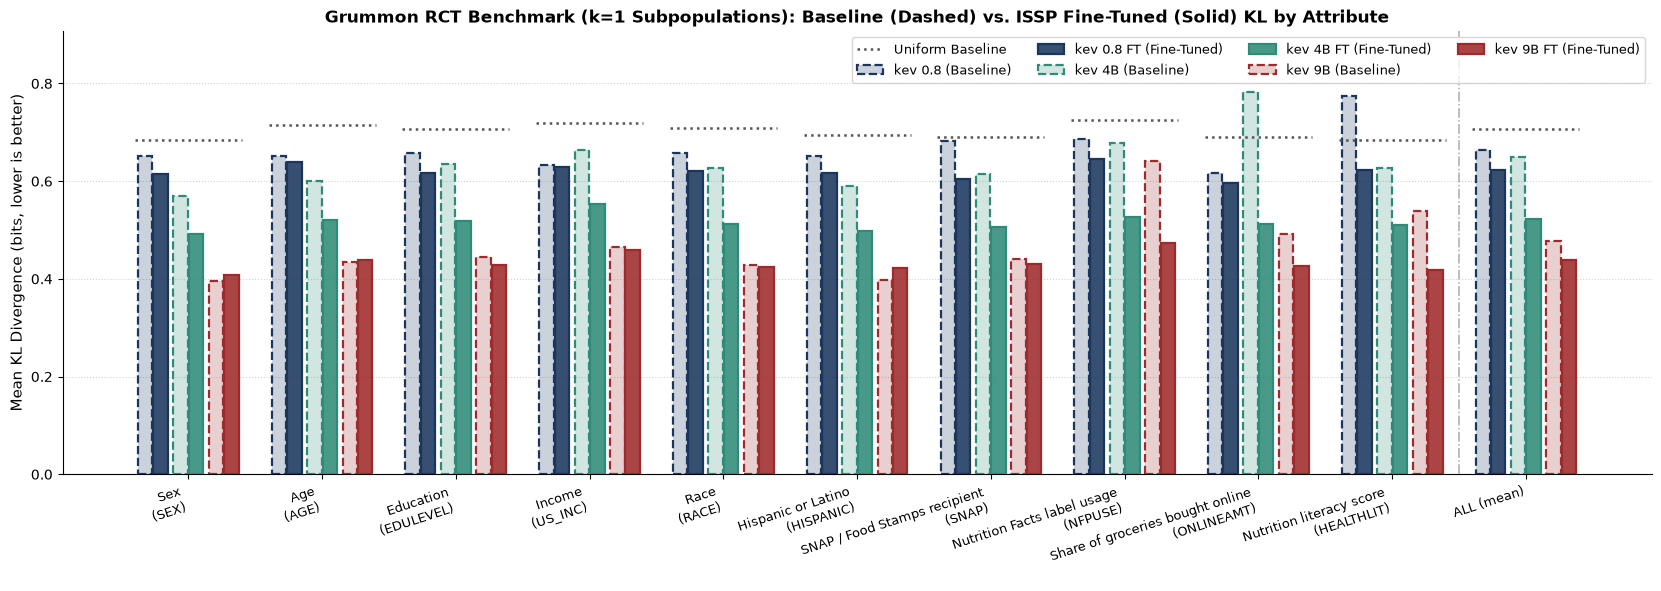

In [13]:
from matplotlib.colors import to_rgba

attrs = list(attr_kl_df.index)
x = np.arange(len(attrs), dtype=float)

size_groups = [
    ("0.8B", "kev 0.8", "kev 0.8 FT", LANCET_PALETTE[0]),
    ("4B", "kev 4B", "kev 4B FT", LANCET_PALETTE[2]),
    ("9B", "kev 9B", "kev 9B FT", LANCET_PALETTE[1]),
]

bar_w = 0.115
pair_gap = 0.035
group_span = 2 * bar_w
group_step = group_span + pair_gap
group_centers = (np.arange(len(size_groups)) - (len(size_groups) - 1) / 2.0) * group_step

fig, ax = plt.subplots(figsize=(16.5, 5.8), constrained_layout=True)

for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
    c_offset = group_centers[g_idx]
    base_pos = x + c_offset - bar_w / 2.0
    ft_pos = x + c_offset + bar_w / 2.0

    ax.bar(
        base_pos,
        attr_kl_df[base_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.22),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="--",
        label=f"{base_col} (Baseline)",
        zorder=3,
    )
    ax.bar(
        ft_pos,
        attr_kl_df[ft_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.88),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="-",
        label=f"{ft_col} (Fine-Tuned)",
        zorder=3,
    )

# Plot Uniform reference ticks above each attribute super-group
half_cluster = group_centers[-1] + bar_w + 0.02
for i, u_val in enumerate(attr_kl_df["Uniform"].values):
    ax.hlines(
        u_val,
        x[i] - half_cluster,
        x[i] + half_cluster,
        colors="#555555",
        linestyles=":",
        linewidth=1.8,
        zorder=4,
        label="Uniform Baseline" if i == 0 else None,
    )

# Vertical separator before ALL (mean)
ax.axvline(len(attrs) - 1.5, color="#888888", linestyle="-.", linewidth=1.1, alpha=0.7)

xtick_labels = [
    f"{PERSONA_NAMES[a]}\n({a})" if a in PERSONA_NAMES else a
    for a in attrs
]
ax.set_xticks(x)
ax.set_xticklabels(xtick_labels, rotation=18, ha="right", fontsize=9.5)
ax.set_ylabel("Mean KL Divergence (bits, lower is better)", fontsize=11)
ax.set_title(
    "Grummon RCT Benchmark (k=1 Subpopulations): Baseline (Dashed) vs. ISSP Fine-Tuned (Solid) KL by Attribute",
    fontsize=12.5,
    fontweight="bold",
)
ax.set_ylim(0, max(attr_kl_df[model_cols].max()) * 1.16)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(ncol=4, frameon=True, fontsize=9.5, loc="upper right")
plt.show()

=== Mean KL: In-Training (ISSP) vs. Out-of-Sample (New) Persona Attributes ===


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
In-Training (mean),0.7118,0.6456,0.6260,0.6342,0.5319,0.4474,0.4421
Out-of-Sample (mean),0.7007,0.6805,0.6203,0.6642,0.5135,0.5082,0.4351
ALL (mean),0.7061,0.6633,0.6231,0.6495,0.5225,0.4783,0.4385


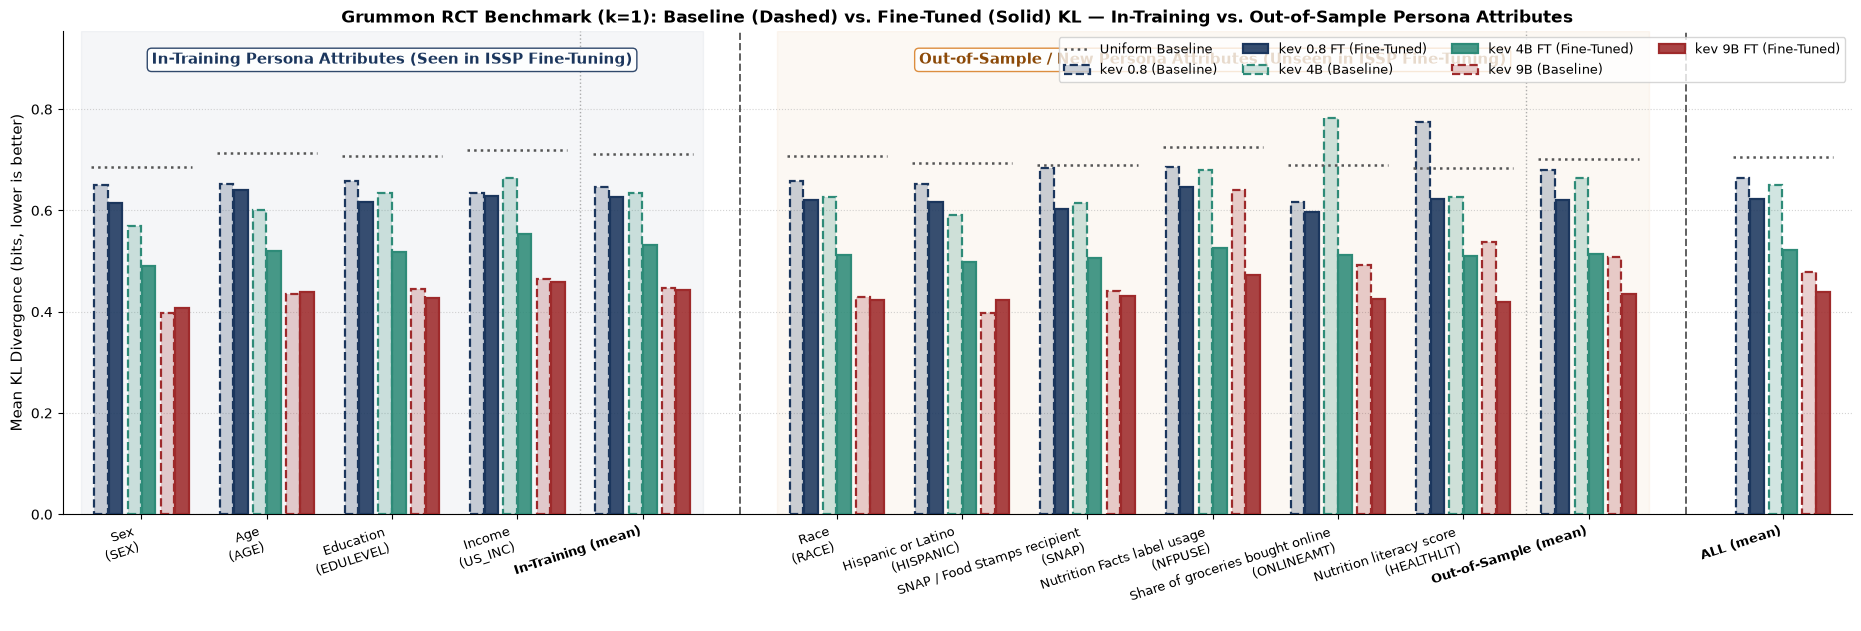

In [14]:
from matplotlib.colors import to_rgba

# In-Training attributes (present in US-ISSP training data) vs. Out-of-Sample / New attributes (unseen during training)
IN_TRAIN_ATTRS = ["SEX", "AGE", "EDULEVEL", "US_INC"]
NEW_ATTRS = ["RACE", "HISPANIC", "SNAP", "NFPUSE", "ONLINEAMT", "HEALTHLIT"]

if set(IN_TRAIN_ATTRS + NEW_ATTRS) != set(DEMO_COLS):
    raise ValueError(f"Attribute partition mismatch: {set(IN_TRAIN_ATTRS + NEW_ATTRS) ^ set(DEMO_COLS)}")

in_train_mask = kl_k1_df["attribute"].isin(IN_TRAIN_ATTRS)
new_attr_mask = kl_k1_df["attribute"].isin(NEW_ATTRS)

grouped_attr_kl_df = pd.concat([
    attr_kl_df.loc[IN_TRAIN_ATTRS],
    pd.DataFrame([kl_k1_df.loc[in_train_mask, model_cols].mean()], index=["In-Training (mean)"]),
    attr_kl_df.loc[NEW_ATTRS],
    pd.DataFrame([kl_k1_df.loc[new_attr_mask, model_cols].mean()], index=["Out-of-Sample (mean)"]),
    pd.DataFrame([kl_k1_df[model_cols].mean()], index=["ALL (mean)"]),
])

print("=== Mean KL: In-Training (ISSP) vs. Out-of-Sample (New) Persona Attributes ===")
display(
    grouped_attr_kl_df.loc[["In-Training (mean)", "Out-of-Sample (mean)", "ALL (mean)"]].round(4)
)

plot_rows = list(grouped_attr_kl_df.index)
# Add visual spacing gaps between the 3 sections: In-Training (5 bars), Out-of-Sample (7 bars), ALL (1 bar)
n_in = len(IN_TRAIN_ATTRS) + 1
n_new = len(NEW_ATTRS) + 1
section_gap = 0.55

x_grouped = np.concatenate([
    np.arange(n_in, dtype=float),
    np.arange(n_in, n_in + n_new, dtype=float) + section_gap,
    np.array([n_in + n_new + 2 * section_gap], dtype=float),
])

size_groups = [
    ("0.8B", "kev 0.8", "kev 0.8 FT", LANCET_PALETTE[0]),
    ("4B", "kev 4B", "kev 4B FT", LANCET_PALETTE[2]),
    ("9B", "kev 9B", "kev 9B FT", LANCET_PALETTE[1]),
]

bar_w = 0.115
pair_gap = 0.035
group_step = 2 * bar_w + pair_gap
group_centers = (np.arange(len(size_groups)) - (len(size_groups) - 1) / 2.0) * group_step

fig, ax = plt.subplots(figsize=(18.5, 6.2), constrained_layout=True)

y_max = float(grouped_attr_kl_df[model_cols].to_numpy().max()) * 1.22

# Subtle background spans for the two attribute regimes
in_left, in_right = x_grouped[0] - 0.48, x_grouped[n_in - 1] + 0.48
new_left, new_right = x_grouped[n_in] - 0.48, x_grouped[n_in + n_new - 1] + 0.48
ax.axvspan(in_left, in_right, color=LANCET_PALETTE[0], alpha=0.045, zorder=0)
ax.axvspan(new_left, new_right, color=LANCET_PALETTE[3], alpha=0.055, zorder=0)

for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
    c_offset = group_centers[g_idx]
    base_pos = x_grouped + c_offset - bar_w / 2.0
    ft_pos = x_grouped + c_offset + bar_w / 2.0

    ax.bar(
        base_pos,
        grouped_attr_kl_df[base_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.22),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="--",
        label=f"{base_col} (Baseline)",
        zorder=3,
    )
    ax.bar(
        ft_pos,
        grouped_attr_kl_df[ft_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.88),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="-",
        label=f"{ft_col} (Fine-Tuned)",
        zorder=3,
    )

half_cluster = group_centers[-1] + bar_w + 0.02
for i, u_val in enumerate(grouped_attr_kl_df["Uniform"].values):
    ax.hlines(
        u_val,
        x_grouped[i] - half_cluster,
        x_grouped[i] + half_cluster,
        colors="#555555",
        linestyles=":",
        linewidth=1.8,
        zorder=4,
        label="Uniform Baseline" if i == 0 else None,
    )

# Dividers between sections and before each section's summary mean
ax.axvline((x_grouped[n_in - 2] + x_grouped[n_in - 1]) / 2.0, color="#999999", linestyle=":", linewidth=1.0, alpha=0.8)
ax.axvline((x_grouped[n_in - 1] + x_grouped[n_in]) / 2.0, color="#444444", linestyle="--", linewidth=1.4, alpha=0.85)
ax.axvline((x_grouped[n_in + n_new - 2] + x_grouped[n_in + n_new - 1]) / 2.0, color="#999999", linestyle=":", linewidth=1.0, alpha=0.8)
ax.axvline((x_grouped[n_in + n_new - 1] + x_grouped[-1]) / 2.0, color="#444444", linestyle="--", linewidth=1.4, alpha=0.85)

# Section header banners
ax.text(
    (in_left + in_right) / 2.0,
    y_max * 0.94,
    "In-Training Persona Attributes (Seen in ISSP Fine-Tuning)",
    ha="center",
    va="center",
    fontsize=10.5,
    fontweight="bold",
    color=LANCET_PALETTE[0],
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": LANCET_PALETTE[0], "alpha": 0.9},
)
ax.text(
    (new_left + new_right) / 2.0,
    y_max * 0.94,
    "Out-of-Sample / New Persona Attributes (Unseen in ISSP Fine-Tuning)",
    ha="center",
    va="center",
    fontsize=10.5,
    fontweight="bold",
    color="#8C4A08",
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": LANCET_PALETTE[3], "alpha": 0.9},
)

xtick_labels = [
    f"{PERSONA_NAMES[a]}\n({a})" if a in PERSONA_NAMES else a
    for a in plot_rows
]
ax.set_xticks(x_grouped)
ax.set_xticklabels(xtick_labels, rotation=18, ha="right", fontsize=9.5)
for tick_lbl, r_name in zip(ax.get_xticklabels(), plot_rows):
    if "mean" in r_name:
        tick_lbl.set_fontweight("bold")

ax.set_xlim(in_left - 0.15, x_grouped[-1] + 0.55)
ax.set_ylim(0, y_max)
ax.set_ylabel("Mean KL Divergence (bits, lower is better)", fontsize=11)
ax.set_title(
    "Grummon RCT Benchmark (k=1): Baseline (Dashed) vs. Fine-Tuned (Solid) KL — In-Training vs. Out-of-Sample Persona Attributes",
    fontsize=12.5,
    fontweight="bold",
)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(ncol=4, frameon=True, fontsize=9.2, loc="upper right")
plt.show()

In [15]:
print("=== Mean KL by Trial Arm (eval_records_k1) ===")
arm_kl_df = kl_k1_df.groupby("arm", sort=False)[model_cols].mean()
arm_kl_df.loc["ALL (mean)"] = kl_k1_df[model_cols].mean()
display(arm_kl_df.round(4))

=== Mean KL by Trial Arm (eval_records_k1) ===


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
arm,,,,,,,
Positive,0.7941,0.8162,0.7048,0.7086,0.5459,0.5419,0.4795
Positive+NutritionInfo,0.7708,0.6406,0.6409,0.6015,0.5095,0.4855,0.4465
Positive+HighIn,0.7059,0.6459,0.6416,0.7026,0.5669,0.4574,0.4649
HighIn,0.6108,0.5600,0.5930,0.5834,0.5081,0.3899,0.4315
Spectrum,0.6413,0.7168,0.5526,0.7206,0.5161,0.5497,0.3980
NutritionInfo,0.7201,0.6062,0.6094,0.5831,0.4901,0.4488,0.4128
ALL (mean),0.7061,0.6633,0.6231,0.6495,0.5225,0.4783,0.4385


In [14]:
print("=== Mean KL by Survey Item (eval_records_k1) ===")
item_kl_df = kl_k1_df.groupby(["type", "v"], sort=False)[model_cols].mean()
display(item_kl_df.round(4))

=== Mean KL by Survey Item (eval_records_k1) ===


Uniform  kev 0.8  kev 0.8 FT  kev 4B  kev 4B FT  \
type   v                                                                    
choice idbev               0.6958   0.7705      0.8443  0.9309     0.8473   
       idbread             0.5662   0.6464      0.7019  0.5347     0.5148   
       idcereal            1.0595   1.3968      1.3110  1.3908     1.2007   
       idsoup              0.5497   0.5164      0.5264  0.5678     0.6135   
       idsnack             0.9327   0.8726      1.0380  0.9684     0.8665   
       idmeal              0.3163   0.2589      0.3184  0.3043     0.2961   
       rnoticed_trial      0.0646   0.1222      0.0398  0.1092     0.0305   
       rused_trial         0.0306   0.0580      0.0556  0.0721     0.0583   
score  elaborationhealth   0.2294   0.1516      0.1089  0.1897     0.1967   
       raffect_worried     0.7324   0.5749      0.4380  0.4317     0.4192   
       raffect_scared      1.1530   0.9165      0.8507  0.5997     0.6828   
       raffect_guilty      0.6074   0.4153      0.3538  0.2576     0.2287   
       raffect_ashamed     0.9196   0.7514      0.6909  0.5945     0.4509   
       raffect_sad         1.1672   0.9391      0.8167  0.6898     0.6008   
       rhelp               0.5363   0.1722      0.2639  0.3556     0.1741   
       runderstand         0.7632   1.1161      0.7108  0.5871     0.4579   
       rtrust              0.7323   0.7227      0.4736  0.4450     0.3196   
       rsupport            0.4965   0.4781      0.4270  0.3954     0.2824   
       feltreal            0.7048   0.2927      0.4601  0.6196     0.4528   
       picksimilar         1.2191   1.2984      1.2386  1.7590     1.0730   
       similarusual        1.1752   1.3008      1.2677  1.6843     1.0850   

                          kev 9B  kev 9B FT  
type   v                                     
choice idbev              0.6286     0.5627  
       idbread            0.5672     0.4792  
       idcereal           0.6321     0.9493  
       idsoup             0.6198     0.4831  
       idsnack            0.5112     0.6803  
       idmeal             0.2733     0.2241  
       rnoticed_trial     0.4171     0.0349  
       rused_trial        0.1108     0.0412  
score  elaborationhealth  0.3030     0.1718  
       raffect_worried    0.3615     0.3617  
       raffect_scared     0.5193     0.5432  
       raffect_guilty     0.3052     0.1954  
       raffect_ashamed    0.4097     0.3333  
       raffect_sad        0.6473     0.4403  
       rhelp              0.2290     0.1882  
       runderstand        0.3667     0.5961  
       rtrust             0.3030     0.2496  
       rsupport           0.3975     0.2715  
       feltreal           0.3172     0.3649  
       picksimilar        1.2435     1.1248  
       similarusual       0.7842     0.8094

In [15]:
# Win-rate (% of k=1 subpopulation-question records where Fine-Tuned KL < Baseline KL)
win_rates = {}
for size_label, base_col, ft_col in [
    ("0.8B (FT vs Baseline)", "kev 0.8", "kev 0.8 FT"),
    ("4B (FT vs Baseline)", "kev 4B", "kev 4B FT"),
    ("9B (FT vs Baseline)", "kev 9B", "kev 9B FT"),
]:
    win_rates[size_label] = {
        "All records (%)": float((kl_k1_df[ft_col] < kl_k1_df[base_col]).mean() * 100.0),
        "Choice records (%)": float((kl_k1_df.loc[kl_k1_df["type"] == "choice", ft_col] < kl_k1_df.loc[kl_k1_df["type"] == "choice", base_col]).mean() * 100.0),
        "Score records (%)": float((kl_k1_df.loc[kl_k1_df["type"] == "score", ft_col] < kl_k1_df.loc[kl_k1_df["type"] == "score", base_col]).mean() * 100.0),
    }
print("=== Fine-Tuned vs. Baseline KL Win Rate on eval_records_k1 ===")
display(pd.DataFrame(win_rates).T.round(2))

=== Fine-Tuned vs. Baseline KL Win Rate on eval_records_k1 ===


,All records (%),Choice records (%),Score records (%)
0.8B (FT vs Baseline),57.08,44.17,64.75
4B (FT vs Baseline),66.92,58.00,72.23
9B (FT vs Baseline),55.34,52.44,57.06


## 4. Respondent-level predictions and OLS regression benchmark

In [5]:
ID_ITEMS = [q[0] for q in QUESTIONS[:6]]
if ID_ITEMS != ["idbev", "idbread", "idcereal", "idsoup", "idsnack", "idmeal"]:
    raise ValueError(f"Unexpected product-choice items: {ID_ITEMS}")
PERSONA_COLS = [c for c in PERSONA_NAMES if c != "c_alphan"]

resp_item_df = grummon_df[grummon_df["v"].isin(ID_ITEMS)].reset_index(drop=True)

# One record per participant x item; persona = every non-missing attribute of that participant.
resp_records = []
for row in resp_item_df.to_dict("records"):
    cols = [c for c in PERSONA_COLS if pd.notna(row[c])]
    rec = make_record(row, cols)
    rec["participantid"] = row["participantid"]
    resp_records.append(rec)

# Identical (arm, item, persona) prompts give identical predictions, so run each once.
unique_records, rec_to_unique, _seen = [], [], {}
for rec in resp_records:
    key = (rec["arm"], rec["v"], tuple(sorted(rec["personas"].items())))
    if key not in _seen:
        _seen[key] = len(unique_records)
        unique_records.append(rec)
    rec_to_unique.append(_seen[key])

print(f"participants: {resp_item_df['participantid'].nunique():,}")
print(f"participant x item records: {len(resp_records):,}")
print(f"unique (arm, item, persona) prompts: {len(unique_records):,}")
print(json.dumps(make_view(resp_records[0]), indent=2))


participants: 5,633
participant x item records: 33,798
unique (arm, item, persona) prompts: 31,224
{
  "state": "Country: United States\nSex: Female\nAge: 30-49\nEducation: Some college or technical school\nIncome: $50,000 - $74,999\nRace: White\nHispanic or Latino: No\nSNAP / Food Stamps recipient: No\nNutrition Facts label usage: Sometimes\nShare of groceries bought online: 25-49%\nNutrition literacy score: 3 out of 4",
  "questions": {
    "Positive:idbev": {
      "type": "choice",
      "instructions": "Click on the product you think is healthier, or click 'They're the same' if you think the two products are equally healthy.",
      "criteria": {
        "Ocean Spray 100% Cranberry juice": "Front-of-package label: None",
        "Ocean Spray Cranberry Juice Cocktail": "Front-of-package label: None",
        "They're the same": null
      },
      "target": {
        "Ocean Spray 100% Cranberry juice": 0.0,
        "Ocean Spray Cranberry Juice Cocktail": 0.0,
        "They're the s

In [8]:
import gc, sys, traceback

import torch
from tqdm.auto import tqdm

sys.path.insert(0, "kev")
from models.kev_pointer import Checkpoint, KevPointerModel, LoadOptions


def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    for attr in ("last_value", "last_type", "last_exc"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True, autocast_bf16=False):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch]
        if autocast_bf16:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits_batch = model.forward([enc for enc, _ in prepared])
        else:
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


In [15]:
model_specs = [
    ("kev 0.8", "jaredpalmer/kev-0.8b", None),
    ("kev 0.8 FT", "runs/kev-0.8b-stage4-mix/best", 1.0),
    ("kev 4B", "jaredpalmer/kev-4b", None),
    ("kev 4B FT", "runs/kev-4b-stage2-k2/best", 1.0),
    ("kev 9B", "jaredpalmer/kev-9b", None),
    ("kev 9B FT", "runs/kev-9b-stage2-k2/best", 1.0),
]

RESP_MODELS = tuple(label for label, _, _ in model_specs)
resp_specs = [s for s in model_specs if s[0] in RESP_MODELS]
if [s[0] for s in resp_specs] != list(RESP_MODELS):
    raise ValueError(f"model_specs is missing one of {RESP_MODELS}")

if "resp_unique_preds" not in globals():
    resp_unique_preds = {}

for label, ckpt_id, temp_override in resp_specs:
    if label in resp_unique_preds:
        if len(resp_unique_preds[label]) != len(unique_records):
            raise ValueError(f"{label}: cached predictions have a different length; delete resp_unique_preds and rerun")
        continue
    if "model" in globals():
        del model
    free_gpu()
    ck = Checkpoint(ckpt_id)
    tok, net = ck.load("cuda", LoadOptions(dtype=torch.bfloat16, temperature=1.0))
    model = KevPointerModel(net, tok, ck.meta, "loaded")
    del ck, tok, net
    model.net.head.temperature = float(model.meta.temperature) if temp_override is None else float(temp_override)
    print(f"{label} ({ckpt_id}): temperature={model.net.head.temperature:.2f}")
    resp_unique_preds[label] = predict_probs(model, unique_records, batch_size=64, show_progress=True, autocast_bf16=True)

if "model" in globals():
    del model
free_gpu()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

kev 4B (jaredpalmer/kev-4b): temperature=2.41


... (14 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

kev 9B FT (runs/kev-9b-stage2-k2/best): temperature=1.00


predict:   0%|          | 0/488 [00:00<?, ?batch/s]

In [16]:
resp_pred_df = pd.DataFrame({
    "participantid": [r["participantid"] for r in resp_records],
    "arm": [r["arm"] for r in resp_records],
    "v": [r["v"] for r in resp_records],
    "human": [float(r["human_dist"][0]) for r in resp_records],  # 1 = chose Option 1 (healthier)
})
for label in RESP_MODELS:
    preds = resp_unique_preds[label]
    if len(preds) != len(unique_records):
        raise ValueError(f"{label}: expected {len(unique_records)} predictions, got {len(preds)}")
    resp_pred_df[label] = [float(preds[u][0]) for u in rec_to_unique]
    if not resp_pred_df[label].between(0.0, 1.0).all():
        raise ValueError(f"{label}: NaN or out-of-range probabilities in predictions")

# Participant-level DV: mean over the items each participant answered.
participant_df = resp_pred_df.groupby("participantid").agg(
    arm=("arm", "first"),
    n_items=("v", "size"),
    human=("human", "mean"),
    **{label: (label, "mean") for label in RESP_MODELS},
).reset_index()
participant_df = participant_df.merge(
    resp_df[["participantid", *PERSONA_COLS]], on="participantid", how="left", validate="one_to_one"
)
if not (participant_df["n_items"] == len(ID_ITEMS)).all():
    raise ValueError(f"Participants with != {len(ID_ITEMS)} items:\n{participant_df['n_items'].value_counts().to_string()}")
arm_order = ["Positive", "NutritionInfo", "HighIn", "Positive+NutritionInfo", "Positive+HighIn", "Spectrum"]
arm_means = participant_df.groupby("arm")[["human", *RESP_MODELS]].mean().loc[arm_order]
arm_effects = arm_means - arm_means.loc["Positive"]  # effect vs. reference arm
print("\nMean DV by arm")
display(arm_means.round(3))
print("Effect vs. Positive (compare to eTable 9: +0.184, +0.053, +0.179, +0.118, +0.108)")
display(arm_effects.round(3))


Mean DV by arm


,human,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
arm,,,,,,,
Positive,0.631,0.250,0.228,0.257,0.274,0.358,0.320
NutritionInfo,0.815,0.295,0.285,0.333,0.352,0.514,0.443
HighIn,0.685,0.356,0.240,0.230,0.230,0.361,0.305
Positive+NutritionInfo,0.810,0.301,0.281,0.355,0.359,0.497,0.431
Positive+HighIn,0.750,0.301,0.260,0.268,0.284,0.386,0.332
Spectrum,0.739,0.276,0.289,0.308,0.285,0.374,0.362


Effect vs. Positive (compare to eTable 9: +0.184, +0.053, +0.179, +0.118, +0.108)


,human,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
arm,,,,,,,
Positive,0.000,0.000,0.000,0.000,0.000,0.000,0.000
NutritionInfo,0.184,0.045,0.058,0.077,0.078,0.156,0.123
HighIn,0.054,0.106,0.012,-0.026,-0.044,0.003,-0.015
Positive+NutritionInfo,0.179,0.051,0.053,0.098,0.085,0.139,0.111
Positive+HighIn,0.119,0.051,0.032,0.011,0.010,0.028,0.012
Spectrum,0.108,0.027,0.061,0.052,0.012,0.017,0.042


In [17]:
import statsmodels.formula.api as smf
from scipy.stats import spearmanr

OUTCOMES = ["human", *RESP_MODELS]
TREAT_ARMS = [a for a in arm_order if a != "Positive"]

betas = {}
for y in OUTCOMES:
    d = participant_df[["arm", y]].rename(columns={y: "y"})
    fit = smf.ols("y ~ C(arm, Treatment(reference='Positive'))", data=d).fit(cov_type="HC1")
    betas[y] = pd.Series(
        {arm: float(fit.params[f"C(arm, Treatment(reference='Positive'))[T.{arm}]"]) for arm in TREAT_ARMS},
        name=y,
    )

beta_df = pd.DataFrame(betas)
human_b = beta_df["human"]
if (human_b == 0).any():
    raise ValueError("Zero human beta encountered in MAPE denominator")

comparison_df = pd.DataFrame({
    y: {
        "MAPE (%)": float(((beta_df[y] - human_b).abs() / human_b.abs()).mean() * 100.0),
        "MSE": float(((beta_df[y] - human_b) ** 2).mean()),
        "MAE": float((beta_df[y] - human_b).abs().mean()),
        "Spearman rho": float(spearmanr(beta_df[y], human_b).statistic),
    }
    for y in RESP_MODELS
}).T

print("=== Treatment-Effect Coefficients vs. Positive (beta) ===")
display(beta_df.round(4))
print("=== Decision Model Comparison Against Human Betas ===")
display(comparison_df.round(4))


=== Treatment-Effect Coefficients vs. Positive (beta) ===


,human,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
NutritionInfo,0.1844,0.0450,0.0575,0.0766,0.0777,0.1557,0.1230
HighIn,0.0541,0.1062,0.0124,-0.0264,-0.0440,0.0027,-0.0148
Positive+NutritionInfo,0.1788,0.0514,0.0526,0.0982,0.0852,0.1392,0.1113
Positive+HighIn,0.1194,0.0512,0.0319,0.0114,0.0105,0.0283,0.0122
Spectrum,0.1083,0.0266,0.0610,0.0517,0.0116,0.0166,0.0425


=== Decision Model Comparison Against Human Betas ===


,MAPE (%),MSE,MAE,Spearman rho
kev 0.8,75.1719,0.0099,0.0938,-0.3
kev 0.8 FT,66.6781,0.0087,0.0859,0.4
kev 4B,79.0408,0.0079,0.0867,0.8
kev 4B FT,94.4402,0.0102,0.1009,0.8
kev 9B,58.7621,0.0044,0.0605,1.0
kev 9B FT,69.8177,0.0058,0.0742,0.9


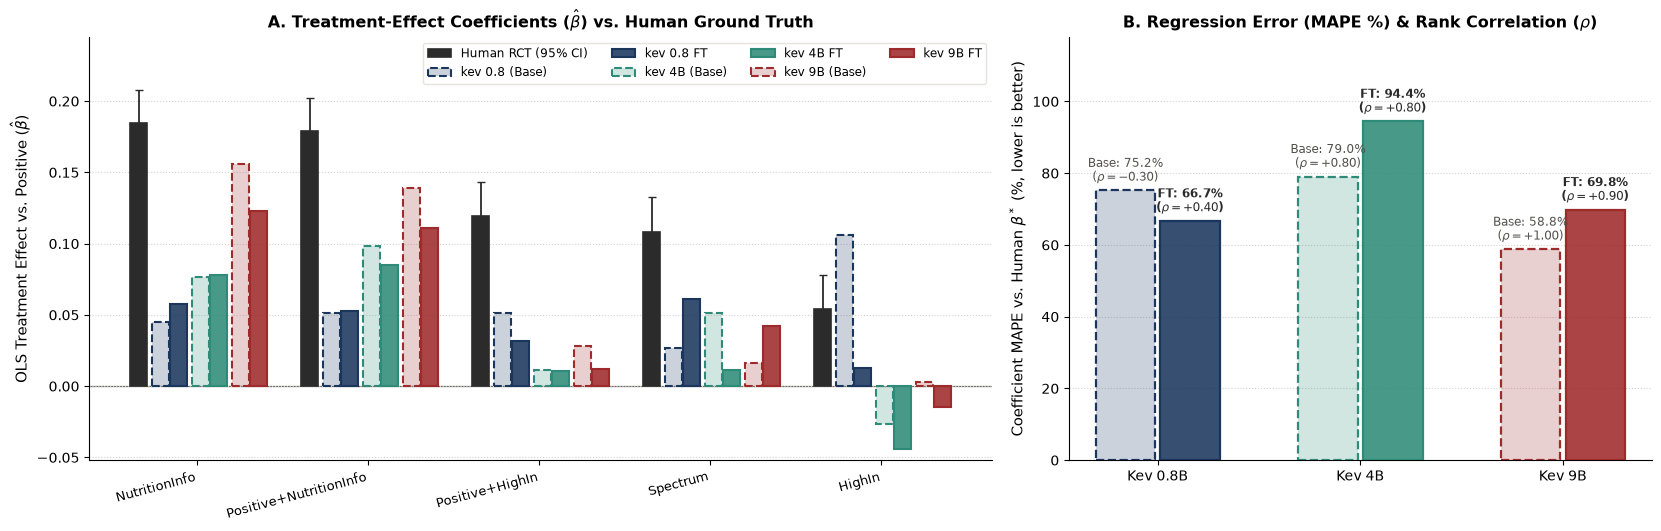

In [19]:
from matplotlib.colors import to_rgba

# Sort arms by human ground-truth treatment effect (descending)
sorted_arms = list(beta_df["human"].sort_values(ascending=False).index)
plot_beta = beta_df.loc[sorted_arms]

human_fit = smf.ols("human ~ C(arm, Treatment(reference='Positive'))", data=participant_df).fit(cov_type="HC1")
human_se = pd.Series(
    {arm: float(human_fit.bse[f"C(arm, Treatment(reference='Positive'))[T.{arm}]"]) for arm in sorted_arms}
)

size_groups = [
    ("0.8B", "kev 0.8", "kev 0.8 FT", LANCET_PALETTE[0]),
    ("4B", "kev 4B", "kev 4B FT", LANCET_PALETTE[2]),
    ("9B", "kev 9B", "kev 9B FT", LANCET_PALETTE[1]),
]

x = np.arange(len(sorted_arms), dtype=float)
bar_w = 0.105
pair_gap = 0.025
# 7 bars per arm: Human + 3 (Base, FT) pairs
slot_offsets = [
    -3.25 * bar_w,
    -2.05 * bar_w, -1.05 * bar_w,
    -0.05 * bar_w + pair_gap, 0.95 * bar_w + pair_gap,
    1.95 * bar_w + 2 * pair_gap, 2.95 * bar_w + 2 * pair_gap,
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 5.2), constrained_layout=True, gridspec_kw={"width_ratios": [1.55, 1.0]})

# Panel A: Unscaled OLS treatment-effect coefficients (beta) by arm
h_pos = x + slot_offsets[0]
ax1.bar(
    h_pos,
    plot_beta["human"].values,
    width=bar_w * 0.94,
    facecolor="#2B2B2B",
    edgecolor="#2B2B2B",
    linewidth=1.2,
    label="Human RCT (95% CI)",
    zorder=3,
)
ax1.errorbar(
    h_pos, plot_beta["human"].values, yerr=1.96 * human_se.values,
    fmt="none", ecolor="#2B2B2B", elinewidth=1.3, capsize=3.0, zorder=4,
)

for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
    base_pos = x + slot_offsets[1 + 2 * g_idx]
    ft_pos = x + slot_offsets[2 + 2 * g_idx]

    ax1.bar(
        base_pos,
        plot_beta[base_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.22),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.5,
        linestyle="--",
        label=f"{base_col} (Base)",
        zorder=3,
    )
    ax1.bar(
        ft_pos,
        plot_beta[ft_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.88),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.5,
        linestyle="-",
        label=ft_col,
        zorder=3,
    )

ax1.axhline(0.0, color="#6E6A64", linewidth=0.9, zorder=1)
ax1.set_xticks(x)
ax1.set_xticklabels(sorted_arms, rotation=15, ha="right", fontsize=9.5)
ax1.set_ylabel("OLS Treatment Effect vs. Positive ($\\hat{\\beta}$)", fontsize=10.5)
ax1.set_title("A. Treatment-Effect Coefficients ($\\hat{\\beta}$) vs. Human Ground Truth", fontsize=11.5, fontweight="bold")
y_lo = min(0.0, float(plot_beta.to_numpy().min()) * 1.18)
y_hi = float((plot_beta["human"] + 1.96 * human_se).max()) * 1.18
ax1.set_ylim(y_lo, y_hi)
ax1.grid(axis="y", color="#D4D2CC", linestyle=":", zorder=0)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(ncol=4, frameon=True, edgecolor="#E0DED8", fontsize=8.5, loc="upper right")

# Panel B: Direct comparison of MAPE (%) and Spearman rho across 0.8B, 4B, 9B (Base vs. FT)
gx = np.arange(len(size_groups), dtype=float)
gw = 0.32
for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
    b_mape = comparison_df.loc[base_col, "MAPE (%)"]
    f_mape = comparison_df.loc[ft_col, "MAPE (%)"]
    b_rho = comparison_df.loc[base_col, "Spearman rho"]
    f_rho = comparison_df.loc[ft_col, "Spearman rho"]

    ax2.bar(
        gx[g_idx] - gw / 2.0, b_mape, width=gw * 0.92,
        facecolor=to_rgba(color, 0.22), edgecolor=to_rgba(color, 1.0),
        linewidth=1.6, linestyle="--", zorder=3,
    )
    ax2.bar(
        gx[g_idx] + gw / 2.0, f_mape, width=gw * 0.92,
        facecolor=to_rgba(color, 0.88), edgecolor=to_rgba(color, 1.0),
        linewidth=1.6, linestyle="-", zorder=3,
    )
    ax2.text(
        gx[g_idx] - gw / 2.0, b_mape + 1.5,
        f"Base: {b_mape:.1f}%\n($\\rho={b_rho:+.2f}$)",
        ha="center", va="bottom", fontsize=8.3, color="#52514E",
    )
    ax2.text(
        gx[g_idx] + gw / 2.0, f_mape + 1.5,
        f"FT: {f_mape:.1f}%\n($\\rho={f_rho:+.2f}$)",
        ha="center", va="bottom", fontsize=8.3, fontweight="bold", color="#2B2B2B",
    )

ax2.set_xticks(gx)
ax2.set_xticklabels([f"Kev {s[0]}" for s in size_groups], fontsize=10)
ax2.set_ylabel("Coefficient MAPE vs. Human $\\beta^*$ (%, lower is better)", fontsize=10.5)
ax2.set_title("B. Regression Error (MAPE %) & Rank Correlation ($\\rho$)", fontsize=11.5, fontweight="bold")
ax2.set_ylim(0, float(comparison_df["MAPE (%)"].max()) * 1.25)
ax2.grid(axis="y", color="#D4D2CC", linestyle=":", zorder=0)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.show()

In [21]:
# OLS regression with treatment arms + respondent persona covariates
IN_TRAIN_ATTRS = ["SEX", "AGE", "EDULEVEL", "US_INC"]
ALL_PERSONA_ATTRS = list(PERSONA_COLS)

formula_full = (
    "y ~ C(arm, Treatment(reference='Positive')) + "
    + " + ".join(f"C({c})" for c in ALL_PERSONA_ATTRS)
)

reg_df = participant_df.dropna(subset=ALL_PERSONA_ATTRS).copy()
print(f"Complete-case respondents for full persona regression: {len(reg_df):,} / {len(participant_df):,}")

full_betas = {}
for y in OUTCOMES:
    d = reg_df[["arm", *ALL_PERSONA_ATTRS, y]].rename(columns={y: "y"})
    fit = smf.ols(formula_full, data=d).fit(cov_type="HC1")
    full_betas[y] = fit.params.drop("Intercept")

full_beta_df = pd.DataFrame(full_betas)
arm_terms = [t for t in full_beta_df.index if t.startswith("C(arm")]
in_train_terms = [t for t in full_beta_df.index if any(t.startswith(f"C({c})") for c in IN_TRAIN_ATTRS)]
persona_terms = [t for t in full_beta_df.index if not t.startswith("C(arm")]


def compare_beta_subset(df_sub, eps=0.01):
    hb = df_sub["human"]
    return pd.DataFrame({
        m: {
            "MAPE (%)": float(((df_sub[m] - hb).abs() / (hb.abs() + eps)).mean() * 100.0),
            "MSE": float(((df_sub[m] - hb) ** 2).mean()),
            "MAE": float((df_sub[m] - hb).abs().mean()),
            "Spearman rho": float(spearmanr(df_sub[m], hb).statistic),
        }
        for m in RESP_MODELS
    }).T


print("\nMean |beta| magnitude by term group:")
mag_df = pd.DataFrame({
    "Arm terms (5)": full_beta_df.loc[arm_terms].abs().mean(),
    "Persona terms (39)": full_beta_df.loc[persona_terms].abs().mean(),
    "In-train persona terms (20)": full_beta_df.loc[in_train_terms].abs().mean(),
})
display(mag_df.round(4))

print(f"=== 1. All Terms ({len(full_beta_df)} coefficients: 5 Arms + {len(persona_terms)} Persona levels) ===")
display(compare_beta_subset(full_beta_df).round(4))

print(f"=== 2. All Persona Terms Only ({len(persona_terms)} coefficients across 10 attributes) ===")
display(compare_beta_subset(full_beta_df.loc[persona_terms]).round(4))

print(f"=== 3. In-Training ISSP Persona Terms Only ({len(in_train_terms)} coefficients: SEX, AGE, EDULEVEL, US_INC) ===")
display(compare_beta_subset(full_beta_df.loc[in_train_terms]).round(4))

Complete-case respondents for full persona regression: 5,615 / 5,633

Mean |beta| magnitude by term group:


,Arm terms (5),Persona terms (39),In-train persona terms (20)
human,0.1306,0.0461,0.0232
kev 0.8,0.0564,0.0039,0.0028
kev 0.8 FT,0.0434,0.0046,0.0060
kev 4B,0.0529,0.0058,0.0063
kev 4B FT,0.0459,0.0031,0.0041
kev 9B,0.0680,0.0119,0.0080
kev 9B FT,0.0606,0.0039,0.0033


=== 1. All Terms (44 coefficients: 5 Arms + 39 Persona levels) ===


,MAPE (%),MSE,MAE,Spearman rho
kev 0.8,67.2157,0.0052,0.0511,0.3428
kev 0.8 FT,68.5323,0.0052,0.0508,0.2035
kev 4B,69.4083,0.0047,0.0496,0.4383
kev 4B FT,71.5812,0.0051,0.0522,0.3588
kev 9B,69.7615,0.0042,0.0467,0.4213
kev 9B FT,72.0833,0.0046,0.0496,0.2949


=== 2. All Persona Terms Only (39 coefficients across 10 attributes) ===


,MAPE (%),MSE,MAE,Spearman rho
kev 0.8,67.1811,0.0046,0.0455,0.0968
kev 0.8 FT,69.4694,0.0047,0.0462,-0.0986
kev 4B,69.1807,0.0042,0.0446,0.3196
kev 4B FT,69.9135,0.0045,0.0457,0.2138
kev 9B,71.8232,0.0041,0.0446,0.2227
kev 9B FT,73.2166,0.0045,0.0462,0.1115


=== 3. In-Training ISSP Persona Terms Only (20 coefficients: SEX, AGE, EDULEVEL, US_INC) ===


,MAPE (%),MSE,MAE,Spearman rho
kev 0.8,52.1152,0.0017,0.0216,0.4977
kev 0.8 FT,58.0783,0.0019,0.0231,-0.0842
kev 4B,60.0209,0.0015,0.0224,0.1684
kev 4B FT,60.6931,0.0016,0.0231,0.1744
kev 9B,64.5857,0.0017,0.0232,0.2090
kev 9B FT,65.3539,0.0017,0.0239,0.0737


## 5. Export participant responses and benchmark inference on `grummon_US_long.parquet`

### 5.1 Export `grummon_US_long.parquet` and verify human OLS against `ParentFile_wide.csv` and eTable 9

In [12]:
import importlib
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

GRUMMON_DIR = (
    Path(".")
    if Path("ParentFile_wide.csv").exists()
    else Path("data/nutrition/Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases")
)
CODE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "persona.py").exists())
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

import data.persona as persona
importlib.reload(persona)

raw_export_df = pd.read_csv(GRUMMON_DIR / "ParentFile_wide.csv")
for arm_val in raw_export_df["foplcond"]:
    if arm_val not in FOPL_STIMULUS:
        raise ValueError(f"Unexpected foplcond value {arm_val!r}")

export_resp_df = pd.DataFrame({
    "CASEID": "grummon_" + raw_export_df["participantid"].astype(str),
    "participantid": raw_export_df["participantid"].astype(str),
    "arm": raw_export_df["foplcond"],
    "c_alphan": persona.map_persona_series(pd.Series(["United States"] * len(raw_export_df)), "c_alphan", "grummon"),
    "SEX": persona.map_persona_series(raw_export_df["gender"], "SEX", "grummon"),
    "AGE": persona.map_persona_series(raw_export_df["age"], "AGE", "grummon"),
    "EDULEVEL": persona.map_persona_series(raw_export_df["educ"], "EDULEVEL", "grummon"),
    "US_INC": persona.map_persona_series(raw_export_df["income"], "US_INC", "grummon"),
    "RACE": persona.map_persona_series(raw_export_df["racecat"], "RACE", "grummon"),
    "HISPANIC": strict_map(raw_export_df["latino"], LATINO_MAP, "latino"),
    "SNAP": strict_map(raw_export_df["snap"], SNAP_MAP, "snap"),
    "NFPUSE": strict_map(raw_export_df["nfpuse"], NFPUSE_MAP, "nfpuse"),
    "ONLINEAMT": strict_map(raw_export_df["onlineamt"], ONLINE_MAP, "onlineamt"),
    "HEALTHLIT": strict_map(raw_export_df["scr_litall"], HEALTHLIT_MAP, "scr_litall"),
})

OLS_QUESTIONS = [q for q in QUESTIONS if q[0] in PRODUCT_BASE_LABELS]
if [q[0] for q in OLS_QUESTIONS] != ["idbev", "idbread", "idcereal", "idsoup", "idsnack", "idmeal"]:
    raise ValueError(f"Unexpected OLS_QUESTIONS: {[q[0] for q in OLS_QUESTIONS]}")

export_frames = []
for v_name, q_type, q_text, codes, texts in OLS_QUESTIONS:
    valid_mask = raw_export_df[v_name].notna()
    sub = export_resp_df.loc[valid_mask].copy()
    ans_raw = raw_export_df.loc[valid_mask, v_name]

    int_codes = [int(c) for c in codes]
    code_to_text = dict(zip(int_codes, texts, strict=True))
    ans_codes = []
    for val in ans_raw:
        ival = int(val)
        if ival not in code_to_text or float(ival) != float(val):
            raise ValueError(f"{v_name}: unexpected answer {val!r}")
        ans_codes.append(ival)
    ans_texts = [code_to_text[c] for c in ans_codes]

    p1, p2, _ = texts
    arms = sub["arm"].tolist()
    opt_descs_col = [
        [format_product_label(v_name, p1, arm), format_product_label(v_name, p2, arm), None]
        for arm in arms
    ]

    sub["v"] = v_name
    sub["qid"] = sub["arm"] + ":" + v_name
    sub["label"] = sub["arm"] + ": " + v_name
    sub["question"] = [q_text] * len(sub)
    sub["type"] = q_type
    sub["reversed"] = False
    sub["option_codes"] = [list(int_codes)] * len(sub)
    sub["option_texts"] = [list(texts)] * len(sub)
    sub["option_descriptions"] = opt_descs_col
    sub["answer_code"] = ans_codes
    sub["answer_text"] = ans_texts
    export_frames.append(sub.reset_index(drop=True))

grummon_export_df = pd.concat(export_frames, ignore_index=True)

out_parquet = GRUMMON_DIR / "grummon_US_long.parquet"
grummon_export_df.to_parquet(out_parquet, index=False)

in_train_cols = ["SEX", "AGE", "EDULEVEL", "US_INC", "RACE"]
all_10_cols = [*in_train_cols, "HISPANIC", "SNAP", "NFPUSE", "ONLINEAMT", "HEALTHLIT"]
n_unique_10 = len(grummon_export_df.groupby(["qid", *all_10_cols], dropna=False))
n_unique_5 = len(grummon_export_df.groupby(["qid", *in_train_cols], dropna=False))

print(
    f"Saved {out_parquet} ({len(grummon_export_df):,} rows x {grummon_export_df.shape[1]} cols | "
    f"{grummon_export_df['CASEID'].nunique():,} participants x 6 items | "
    f"{grummon_export_df['qid'].nunique()} arm-item qids | "
    f"unique (qid, persona) prompts: {n_unique_10:,} [10 attrs], {n_unique_5:,} [5 in-train attrs])"
)

# Reload exported parquet and run OLS on human data to verify against raw ParentFile_wide.csv and Supplement 2, eTable 9 (p. 18)
check_df = pd.read_parquet(out_parquet)
check_df["y"] = (check_df["answer_code"] == 1).astype(float)

part_check_df = check_df.groupby("CASEID", as_index=False).agg(
    arm=("arm", "first"),
    n_items=("v", "size"),
    y=("y", "mean"),
)
if not (part_check_df["n_items"] == 6).all():
    raise ValueError("Expected every exported participant to have all 6 product-choice items")

fit_part = smf.ols("y ~ C(arm, Treatment(reference='Positive'))", data=part_check_df).fit(cov_type="HC1")
fit_cluster = smf.ols("y ~ C(arm, Treatment(reference='Positive'))", data=check_df).fit(
    cov_type="cluster", cov_kwds={"groups": check_df["CASEID"]}
)

# Direct raw-file OLS benchmark on the 5,633 non-missing respondents in ParentFile_wide.csv
raw_valid = raw_export_df.dropna(subset=["idbev", "idbread", "idcereal", "idsoup", "idsnack", "idmeal"]).copy()
raw_valid["y_raw"] = (
    raw_valid[["idbev", "idbread", "idcereal", "idsoup", "idsnack", "idmeal"]] == 1.0
).mean(axis=1)
fit_raw = smf.ols("y_raw ~ C(foplcond, Treatment(reference='Positive'))", data=raw_valid).fit(cov_type="HC1")

# Published 2-decimal ADEs (and 95% CIs) from Supplement 2, eTable 9 (p. 18), Row 1 ("Correctly identified healthier product")
ETABLE9_PUBLISHED = {
    "NutritionInfo": (0.19, 0.17, 0.22),
    "HighIn": (0.05, 0.03, 0.08),
    "Positive+NutritionInfo": (0.19, 0.16, 0.21),
    "Positive+HighIn": (0.12, 0.10, 0.15),
    "Spectrum": (0.12, 0.09, 0.14),
}

verify_rows = []
for arm, (pub_ade, pub_lo, pub_hi) in ETABLE9_PUBLISHED.items():
    term_exp = f"C(arm, Treatment(reference='Positive'))[T.{arm}]"
    term_raw = f"C(foplcond, Treatment(reference='Positive'))[T.{arm}]"
    b_part = float(fit_part.params[term_exp])
    b_clust = float(fit_cluster.params[term_exp])
    b_raw = float(fit_raw.params[term_raw])
    ci_part = fit_part.conf_int().loc[term_exp]
    if abs(b_part - b_raw) > 1e-12 or abs(b_part - b_clust) > 1e-12:
        raise ValueError(f"OLS mismatch for {arm}: exported={b_part:.12f}, raw={b_raw:.12f}")
    verify_rows.append({
        "Trial arm (vs. Positive)": arm,
        "Raw CSV OLS beta": round(b_raw, 4),
        "Exported Parquet OLS beta (HC1)": round(b_part, 4),
        "Exported Parquet OLS beta (clustered)": round(b_clust, 4),
        "Exported 95% CI": f"({ci_part[0]:.2f}, {ci_part[1]:.2f})",
        "Paper eTable 9 ADE (mixed logit)": f"{pub_ade:.2f} ({pub_lo:.2f}, {pub_hi:.2f})",
    })

print(
    f"\nReference arm (Positive) mean: exported={float(fit_part.params['Intercept']):.4f}, "
    f"raw={float(fit_raw.params['Intercept']):.4f} (exact match to 1e-12):"
)
display(pd.DataFrame(verify_rows).set_index("Trial arm (vs. Positive)"))


Saved grummon_US_long.parquet (33,798 rows x 25 cols | 5,633 participants x 6 items | 36 arm-item qids | unique (qid, persona) prompts: 28,818 [10 attrs], 9,366 [5 in-train attrs])

Reference arm (Positive) mean: exported=0.6309, raw=0.6309 (exact match to 1e-12):


,Raw CSV OLS beta,Exported Parquet OLS beta (HC1),Exported Parquet OLS beta (clustered),Exported 95% CI,Paper eTable 9 ADE (mixed logit)
Trial arm (vs. Positive),,,,,
NutritionInfo,0.1844,0.1844,0.1844,"(0.16, 0.21)","0.19 (0.17, 0.22)"
HighIn,0.0541,0.0541,0.0541,"(0.03, 0.08)","0.05 (0.03, 0.08)"
Positive+NutritionInfo,0.1788,0.1788,0.1788,"(0.16, 0.20)","0.19 (0.16, 0.21)"
Positive+HighIn,0.1194,0.1194,0.1194,"(0.10, 0.14)","0.12 (0.10, 0.15)"
Spectrum,0.1083,0.1083,0.1083,"(0.08, 0.13)","0.12 (0.09, 0.14)"


### 5.2 Step 1: Load data and prepare single-question records & state-grouped evaluation set

In [60]:
# ==============================================================================
# STEP 1: Data loading, record construction, and one-time state grouping
# (Shared abstractions in `data/base.py`, Grummon loader/OLS in `data/grummon.py`)
# ==============================================================================
import importlib
import data.base as base_mod
import data.grummon as grummon_mod
importlib.reload(base_mod)
importlib.reload(grummon_mod)

from data.base import (
    add_one_hot,
    build_long_records,
    group_records_by_state,
    make_long_view,
    make_view,
    pack_views_by_state,
)
from data.grummon import (
    GRUMMON_PERSONA_COLS as EXPORT_PERSONA_COLS,
    evaluate_grummon_ols,
    load_grummon,
)

CKPT_PATH = str(CODE_DIR / "runs/kev-0.8b-stage3-resp-issp+twin2k-bs64/best")

# 1. Load flat respondent-item records (33,798 rows) and pre-built state-grouped bundle (3,652 states)
grummon_records = load_grummon(out_parquet, attr_sets=None, include_country=True, grouped=False)
grummon_grouped = load_grummon(out_parquet, attr_sets=None, include_country=True, grouped=True)

n_unique_q = sum(len(v["questions"]) for v in grummon_grouped["packed_views"])
print(
    f"Prepared Grummon evaluation sets via `data.grummon.load_grummon`:\n"
    f"  - Flat records (grummon_records)        : {len(grummon_records):,} respondent-item rows\n"
    f"  - Unique (state, qid) prompts           : {n_unique_q:,}\n"
    f"  - Unique state views (grummon_grouped)  : {len(grummon_grouped['packed_views']):,} "
    f"(mean {n_unique_q / len(grummon_grouped['packed_views']):.2f} questions/state)"
)


Prepared Grummon evaluation sets via `data.grummon.load_grummon`:
  - Flat records (grummon_records)        : 33,798 respondent-item rows
  - Unique (state, qid) prompts           : 28,818
  - Unique state views (grummon_grouped)  : 3,652 (mean 7.89 questions/state)


### 5.3 Step 2: Define prediction and evaluation functions (single-state vs. shared-state)

In [62]:
# ==============================================================================
# STEP 2: Prediction and evaluation functions (imported from `data.base`)
# ==============================================================================
from data.base import (
    evaluate_model,
    evaluate_pair,
    evaluate_records,
    predict_probs,
    predict_probs_grouped,
)


def free_gpu():
    """Clear Python exception frames and release unused CUDA cached memory."""
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    for attr in ("last_value", "last_type", "last_exc"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    gc.collect()
    torch.cuda.empty_cache()


### 5.4 Step 3: Run evaluation loop (KL/CE, timing, and OLS regression vs. human data)

In [63]:
# ==============================================================================
# STEP 3: Run single-state and shared-state evaluation + OLS vs. human RCT
# ==============================================================================
from models.kev_pointer import Checkpoint, KevPointerModel, LoadOptions

# 1. Load checkpoint ONCE for both single-state and shared-state evaluation
ck = Checkpoint(CKPT_PATH)
tok, net = ck.load("cuda", LoadOptions(dtype=torch.bfloat16, temperature=1.0, cuda_graphs=True, fused=True))
eval_model = KevPointerModel(net, tok, ck.meta, "loaded")
del ck, tok, net
eval_model.net.head.temperature = 1.0

# 2. Evaluate single-state (regular un-grouped inference on grummon_records)
single_summary, single_res_df, single_preds, single_stats = evaluate_model(
    eval_model, grummon_records, batch_size=128, show_progress=True, return_details=True
)

# 3. Evaluate shared-state (grouped inference on pre-built grummon_grouped)
grummon_grouped["encs"] = None
grouped_summary, grouped_res_df, grouped_preds, grouped_stats = evaluate_model(
    eval_model, grummon_grouped, batch_size=128, show_progress=True, return_details=True
)

del eval_model
free_gpu()

# 4. Fit participant-level HC1 OLS regressions via `evaluate_grummon_ols`
ols_single, beta_single_df = evaluate_grummon_ols(grummon_records, single_preds)
ols_shared, beta_shared_df = evaluate_grummon_ols(grummon_grouped, grouped_preds)


def build_eval_row(summary, stats, ols_metrics, ref_total_sec):
    return {
        "Views Run": int(stats["n_views_run"]),
        "Prep (s)": stats["prep_sec"],
        "GPU (s)": stats["gpu_sec"],
        "Total (s)": stats["total_sec"],
        "Speedup (x)": ref_total_sec / stats["total_sec"],
        "Mean CE (bits)": float(summary["ce"]),
        "Mean KL (bits)": float(summary["dist_kl"]),
        **ols_metrics,
    }


eval_comparison_df = pd.DataFrame({
    "Single-State (predict_probs)": build_eval_row(single_summary, single_stats, ols_single, single_stats["total_sec"]),
    "Shared-State (predict_probs_grouped)": build_eval_row(grouped_summary, grouped_stats, ols_shared, single_stats["total_sec"]),
}).T

beta_comparison_df = pd.DataFrame({
    "Human RCT": beta_single_df["human"],
    "Single-State": beta_single_df["model"],
    "Shared-State": beta_shared_df["model"],
    "Abs Diff": (beta_shared_df["model"] - beta_single_df["model"]).abs(),
})

abs_prob_diff = np.abs(np.stack(grouped_preds) - np.stack(single_preds))
print(
    f"=== Checkpoint: {Path(CKPT_PATH).parent.name}/{Path(CKPT_PATH).name} ===\n"
    f"Probability diff across all {len(grummon_records):,} rows: "
    f"mean={float(abs_prob_diff.mean()):.6f}, max={float(abs_prob_diff.max()):.6f}"
)
print("\n--- 1. Timing, KL/CE, and OLS Summary ---")
display(eval_comparison_df.round(4))

print("\n--- 2. Treatment-Effect Coefficients (beta vs. Positive) ---")
display(beta_comparison_df.round(4))


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

predict (single-state):   0%|          | 0/226 [00:00<?, ?batch/s]

predict (shared-state):   0%|          | 0/29 [00:00<?, ?batch/s]

=== Checkpoint: kev-0.8b-stage3-resp-issp+twin2k-bs64/best ===
Probability diff across all 33,798 rows: mean=0.001584, max=0.010675

--- 1. Timing, KL/CE, and OLS Summary ---


,Views Run,Prep (s),GPU (s),Total (s),Speedup (x),Mean CE (bits),Mean KL (bits),OLS MAPE (%),OLS MSE,OLS MAE,Spearman rho
Single-State (predict_probs),28818.0,6.2243,68.2202,74.4463,1.0000,1.6301,1.6301,56.4341,0.005,0.067,0.3
Shared-State (predict_probs_grouped),3652.0,3.2117,35.7286,38.9460,1.9115,1.6305,1.6305,56.4759,0.005,0.067,0.3



--- 2. Treatment-Effect Coefficients (beta vs. Positive) ---


,Human RCT,Single-State,Shared-State,Abs Diff
NutritionInfo,0.1844,0.1019,0.1019,0.0000
HighIn,0.0541,0.1009,0.1010,0.0001
Positive+NutritionInfo,0.1788,0.0916,0.0915,0.0001
Positive+HighIn,0.1194,0.0354,0.0354,0.0000
Spectrum,0.1083,0.0739,0.0739,0.0000


### 5.5 Diagnostic: test single-state vs. shared-state packing on 10 obvious questions

In [ ]:
SHARED_STATE = "\n".join([
    "Country: United States",
    "Sex: Female",
    "Age: 30-49",
    "Education: Graduate or professional degree",
    "Income: $150,000 - $199,999",
    "Race: Asian",
    "Hispanic or Latino: No",
    "SNAP / Food Stamps recipient: No",
    "Nutrition Facts label usage: Always",
    "Nutrition literacy score: 4 out of 4",
])

# 10 obvious / objective questions with varying option counts (2, 3, 4, 5) and varying correct option indices
OBVIOUS_CASES = [
    (
        "q01_country",
        "choice",
        "Which country does this respondent live in?",
        {"United States": None, "Germany": None, "Japan": None},
        0,
    ),
    (
        "q02_sex",
        "choice",
        "What is this respondent's sex?",
        {"Male": None, "Female": None},
        1,
    ),
    (
        "q03_race",
        "choice",
        "What is this respondent's race?",
        {"White": None, "Black or African American": None, "Asian": None, "American Indian or Alaska Native": None},
        2,
    ),
    (
        "q04_snap",
        "choice",
        "Did this respondent receive SNAP / Food Stamps in the past year?",
        {"Yes": None, "No": None},
        1,
    ),
    (
        "q05_education",
        "choice",
        "What is the highest level of education completed by this respondent?",
        {
            "Less than high school": None,
            "High school graduate (or GED)": None,
            "Bachelor's degree": None,
            "Graduate or professional degree": None,
        },
        3,
    ),
    (
        "q06_healthier_clear",
        "choice",
        HEALTHIER_PROMPT,
        {
            "Steamed Broccoli Bowl": "Front-of-package label: [*** BEST (3 stars, blue)]; Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: Low (green) | FDA.gov",
            "Deep-Fried Sugar Donut": "Front-of-package label: [* POOR (1 star, red)]; High In: Saturated Fat, Sodium, Added Sugars | FDA.gov",
            "They're the same": None,
        },
        0,
    ),
    (
        "q07_healthier_swapped",
        "choice",
        HEALTHIER_PROMPT,
        {
            "Double Bacon Soda Combo": "Front-of-package label: [* POOR (1 star, red)]; High In: Saturated Fat, Sodium, Added Sugars | FDA.gov",
            "Unsweetened Spring Water": "Front-of-package label: [*** BEST (3 stars, blue)]; Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: Low (green) | FDA.gov",
            "They're the same": None,
        },
        1,
    ),
    (
        "q08_math",
        "choice",
        "What is 2 + 2?",
        {"3": None, "4": None, "5": None, "22": None},
        1,
    ),
    (
        "q09_nfp_score",
        "score",
        "How often do you use the Nutrition Facts panel when shopping for food?",
        ["Never", "Rarely", "Sometimes", "Most of the time", "Always"],
        4,
    ),
    (
        "q10_water_sugar_score",
        "score",
        "How much do you agree or disagree with the following statement: Plain water has less sugar than regular cola.",
        ["Strongly disagree", "Somewhat disagree", "Neither agree nor disagree", "Somewhat agree", "Strongly agree"],
        4,
    ),
]

# Build 10 separate single-question views (all sharing SHARED_STATE) and pack them with pack_views_by_state
single_10_views = []
for qid, q_type, instr, criteria, exp_idx in OBVIOUS_CASES:
    if q_type == "choice":
        keys = list(criteria.keys())
        target = {k: (1.0 if i == exp_idx else 0.0) for i, k in enumerate(keys)}
    else:
        target = {str(i): (1.0 if i == exp_idx else 0.0) for i in range(len(criteria))}
    single_10_views.append({
        "state": SHARED_STATE,
        "questions": {
            qid: {
                "type": q_type,
                "instructions": instr,
                "criteria": criteria,
                "target": target,
            }
        },
    })

packed_10_views, unpack_10_idx = pack_views_by_state(single_10_views)
obvious_grouped = {
    "records": single_10_views,
    "packed_views": packed_10_views,
    "unpack_idx": unpack_10_idx,
    "encs": None,
    "last_stats": None,
}

# Load checkpoint ONCE and run both single-question inference and shared-state inference on the same model instance
ck = Checkpoint(CKPT_PATH)
tok, net = ck.load("cuda", LoadOptions(dtype=torch.bfloat16, temperature=1.0, cuda_graphs=True, fused=True))
diag_model = KevPointerModel(net, tok, ck.meta, "loaded")
del ck, tok, net
diag_model.net.head.temperature = 1.0

single_probs = predict_probs(diag_model, single_10_views, batch_size=128, show_progress=False, view_fn=lambda v: v)
packed_probs = predict_probs_grouped(diag_model, obvious_grouped, batch_size=128, show_progress=False)

del diag_model
free_gpu()

if len(packed_10_views) != 1 or len(packed_10_views[0]["questions"]) != 10:
    raise AssertionError(f"Expected 1 packed view with 10 questions, got {len(packed_10_views)} views")

# Inspect predicted probabilities side by side
fmt_vec = lambda v: "[" + ", ".join(f"{x:.3f}" for x in v) + "]"
inspect_rows = []
for i, (qid, q_type, instr, criteria, exp_idx) in enumerate(OBVIOUS_CASES):
    opts = list(criteria.keys()) if q_type == "choice" else list(criteria)
    p_single = single_probs[i]
    p_packed = packed_probs[i]

    inspect_rows.append({
        "qid": qid,
        "type": q_type,
        "n_opts": len(opts),
        "expected_opt": f"[{exp_idx}] {opts[exp_idx]}",
        "top_single": f"[{int(np.argmax(p_single))}] {opts[int(np.argmax(p_single))]}",
        "top_packed": f"[{int(np.argmax(p_packed))}] {opts[int(np.argmax(p_packed))]}",
        "P(exp) single": round(float(p_single[exp_idx]), 4),
        "P(exp) packed": round(float(p_packed[exp_idx]), 4),
        "max_diff": round(float(np.max(np.abs(p_single - p_packed))), 5),
        "probs_single": fmt_vec(p_single),
        "probs_packed": fmt_vec(p_packed),
    })

inspect_df = pd.DataFrame(inspect_rows).set_index("qid")
print(f"Packed {len(single_10_views)} views into {len(packed_10_views)} view with {len(packed_10_views[0]['questions'])} questions.")
display(inspect_df)


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Packed 10 views into 1 view with 10 questions.


,type,n_opts,expected_opt,top_single,top_packed,P(exp) single,P(exp) packed,max_diff,probs_single,probs_packed
qid,,,,,,,,,,
q01_country,choice,3,[0] United States,[0] United States,[0] United States,0.9276,0.9277,0.00025,"[0.928, 0.057, 0.015]","[0.928, 0.057, 0.015]"
q02_sex,choice,2,[1] Female,[1] Female,[1] Female,0.9104,0.9095,0.00093,"[0.090, 0.910]","[0.090, 0.910]"
q03_race,choice,4,[2] Asian,[2] Asian,[2] Asian,0.8058,0.8028,0.00338,"[0.133, 0.027, 0.806, 0.034]","[0.137, 0.027, 0.803, 0.033]"
q04_snap,choice,2,[1] No,[1] No,[1] No,0.8842,0.8821,0.00211,"[0.116, 0.884]","[0.118, 0.882]"
q05_education,choice,4,[3] Graduate or professional degree,[3] Graduate or professional degree,[3] Graduate or professional degree,0.7802,0.7831,0.00298,"[0.013, 0.052, 0.154, 0.780]","[0.013, 0.052, 0.151, 0.783]"
q06_healthier_clear,choice,3,[0] Steamed Broccoli Bowl,[0] Steamed Broccoli Bowl,[0] Steamed Broccoli Bowl,0.4455,0.4438,0.00234,"[0.445, 0.177, 0.378]","[0.444, 0.176, 0.380]"
q07_healthier_swapped,choice,3,[1] Unsweetened Spring Water,[2] They're the same,[2] They're the same,0.2410,0.2421,0.00303,"[0.253, 0.241, 0.506]","[0.250, 0.242, 0.508]"
q08_math,choice,4,[1] 4,[0] 3,[0] 3,0.3141,0.3154,0.00145,"[0.331, 0.314, 0.245, 0.110]","[0.330, 0.315, 0.243, 0.111]"
q09_nfp_score,score,5,[4] Always,[2] Sometimes,[2] Sometimes,0.2421,0.2408,0.00211,"[0.116, 0.150, 0.251, 0.242, 0.242]","[0.114, 0.149, 0.251, 0.244, 0.241]"


: 